# Sleep Apnea — Best Combined & Clean Pipeline

This notebook consolidates the strongest parts of the two supplied Sleep Apnea notebooks and removes the stale/duplicated cells that caused `NameError`/`TypeError` risks.

### Included improvements
- reproducible project setup and package verification
- robust, resumable dataset download + record integrity checks
- minute-level HR/HRV feature extraction
- record-level train/validation/test splitting with `c05` + `c06` kept together
- TRAIN-ONLY imputation, scaling, correlation/redundancy analysis, and feature selection
- 4D PCA and 4D autoencoder representations
- TRAIN-ONLY scaling of the autoencoder latent space
- classical RBF-SVM baselines plus validation-tuned AE-SVM
- Qiskit quantum-kernel sanity test
- quantum-angle scaling to `[0, π]` fitted using TRAIN only
- record-balanced 1,000-sample QSVM training subset to keep the quantum experiment computationally practical
- corrected train/validation/test quantum-kernel orientation
- validation-only QSVM `C` tuning
- validation-derived decision-threshold analysis (no hard-coded threshold)
- sigmoid calibration fitted on validation scores and evaluated on the untouched test set
- single-sample prediction pipeline and perturbation-based explainability
- saved CSV/model artifacts and a final generated comparison table

**Important:** all result tables are generated at run time; stale hard-coded metrics from the supplied notebooks are not copied into the final results.

In [1]:
# ============================================================
# STEP 0 — PROJECT SETUP + REPRODUCIBILITY
# ============================================================

import os
import sys
import random
import platform
import shutil
import subprocess
from pathlib import Path

SEED = 42

random.seed(SEED)

# Colab-friendly path, with a local fallback.
if Path("/content").exists():
    PROJECT_DIR = Path("/content/SIH_2026_Apnea")
else:
    PROJECT_DIR = Path.cwd() / "SIH_2026_Apnea"

DATA_DIR = PROJECT_DIR / "data" / "apnea-ecg"
FEATURE_DIR = PROJECT_DIR / "features"
MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"

for folder in [PROJECT_DIR, DATA_DIR, FEATURE_DIR, MODEL_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

PHYSIONET_BASE_URL = "https://physionet.org/files/apnea-ecg/1.0.0/"

LEARNING_RECORDS = (
    [f"a{i:02d}" for i in range(1, 21)]
    + [f"b{i:02d}" for i in range(1, 6)]
    + [f"c{i:02d}" for i in range(1, 11)]
)

OFFICIAL_TEST_RECORDS = [f"x{i:02d}" for i in range(1, 36)]

print("=" * 80)
print("SLEEP APNEA — BEST COMBINED PIPELINE")
print("=" * 80)
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Project:", PROJECT_DIR)
print("Learning records:", len(LEARNING_RECORDS))
print("Seed:", SEED)

try:
    total, used, free = shutil.disk_usage(PROJECT_DIR.anchor or "/")
    print(f"Disk free: {free / 1024**3:.2f} GB")
except Exception:
    pass

SLEEP APNEA — BEST COMBINED PIPELINE
Python: 3.13.15
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
Project: /content/SIH_2026_Apnea
Learning records: 35
Seed: 42
Disk free: 86.94 GB


In [2]:
# ============================================================
# STEP 1 — INSTALL / VERIFY CORE PACKAGES
# ============================================================

def pip_install(packages):
    cmd = [sys.executable, "-m", "pip", "install", "-q"] + packages
    subprocess.check_call(cmd)

pip_install([
    "wfdb",
    "scipy",
    "scikit-learn",
    "pandas",
    "matplotlib",
    "requests",
    "tqdm",
    "joblib",
])

import numpy as np
import pandas as pd
import scipy
import sklearn
import requests
import wfdb
import matplotlib.pyplot as plt
import joblib

print("=" * 80)
print("CORE PACKAGE CHECK")
print("=" * 80)
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("SciPy       :", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("WFDB        :", wfdb.__version__)
print("Requests    :", requests.__version__)

CORE PACKAGE CHECK
NumPy       : 2.1.3
Pandas      : 2.2.3
SciPy       : 1.16.3
Scikit-learn: 1.6.1
WFDB        : 4.3.1
Requests    : 2.32.4


In [3]:
# ============================================================
# STEP 2 — INSTALL / VERIFY PYTORCH + QISKIT
# ============================================================

# PyTorch is normally pre-installed in Colab. Install only if import fails.
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
except Exception:
    pip_install(["torch"])
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset

# Pin the same working quantum versions used by the supplied notebooks.
pip_install([
    "qiskit==2.5.2",
    "qiskit-machine-learning==0.9.1",
])

import qiskit
import qiskit_machine_learning

print("=" * 80)
print("PYTORCH / QISKIT CHECK")
print("=" * 80)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

print("Qiskit:", qiskit.__version__)
print("Qiskit ML:", qiskit_machine_learning.__version__)

PYTORCH / QISKIT CHECK
PyTorch: 2.11.0+cpu
CUDA available: False
Qiskit: 2.5.2
Qiskit ML: 0.9.1


In [4]:
# ============================================================
# STEP 3 — GLOBAL SEEDS / TORCH DETERMINISM
# ============================================================

np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Reproducibility seeds configured:", SEED)

Reproducibility seeds configured: 42


## Dataset acquisition

The learning set contains the 35 labeled records used by the pipeline. The official challenge test records (`x01`–`x35`) are not used because they do not provide reference labels for this supervised evaluation.

The downloader below skips already-complete files, writes through a temporary `.part` file, retries interrupted downloads, and the next integrity step verifies that the resulting WFDB records can actually be read.

In [5]:
# ============================================================
# STEP 4 — ROBUST APNEA-ECG DOWNLOAD
# ============================================================

from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm
import time

REQUIRED_EXTENSIONS = [".dat", ".hea", ".apn", ".qrs"]

session = requests.Session()
session.headers.update({
    "User-Agent": "Sleep-Apnea-Research-Notebook/1.0"
})

def download_file(url, destination, retries=3, timeout=(15, 120)):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.exists() and destination.stat().st_size > 0:
        return {"path": str(destination), "status": "already_exists"}

    part_path = Path(str(destination) + ".part")

    last_error = None

    for attempt in range(1, retries + 1):
        try:
            with session.get(url, stream=True, timeout=timeout) as response:
                response.raise_for_status()

                with open(part_path, "wb") as f:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            f.write(chunk)

            if part_path.stat().st_size == 0:
                raise IOError("Downloaded file is empty.")

            part_path.replace(destination)

            return {
                "path": str(destination),
                "status": "downloaded",
                "bytes": destination.stat().st_size
            }

        except Exception as exc:
            last_error = exc
            if part_path.exists():
                part_path.unlink(missing_ok=True)
            time.sleep(attempt)

    raise RuntimeError(f"Failed to download {url}: {last_error}")

def download_record(record_name):
    results = []
    for ext in REQUIRED_EXTENSIONS:
        filename = f"{record_name}{ext}"
        destination = DATA_DIR / filename
        url = PHYSIONET_BASE_URL + filename
        results.append(download_file(url, destination))
    return record_name, results

download_jobs = {}
for record_name in LEARNING_RECORDS:
    for ext in REQUIRED_EXTENSIONS:
        download_jobs[(record_name, ext)] = DATA_DIR / f"{record_name}{ext}"

missing_before = sum(
    not (path.exists() and path.stat().st_size > 0)
    for path in download_jobs.values()
)

print("Missing/non-empty-check failures before download:", missing_before)

with ThreadPoolExecutor(max_workers=6) as executor:
    futures = {
        executor.submit(download_record, rec): rec
        for rec in LEARNING_RECORDS
    }
    for future in tqdm(as_completed(futures), total=len(futures), desc="Downloading records"):
        rec = futures[future]
        try:
            future.result()
        except Exception as exc:
            print(f"ERROR downloading {rec}: {exc}")

missing_after = sum(
    not (path.exists() and path.stat().st_size > 0)
    for path in download_jobs.values()
)

print("\nMissing/empty files after download:", missing_after)

if missing_after:
    missing_paths = [
        str(path) for path in download_jobs.values()
        if not (path.exists() and path.stat().st_size > 0)
    ]
    raise RuntimeError("Some required files are still missing:\n" + "\n".join(missing_paths))

print("Download stage completed.")

Missing/non-empty-check failures before download: 0



Missing/empty files after download: 0
Download stage completed.


In [6]:
# ============================================================
# STEP 5 — DATASET FILE + WFDB READABILITY CHECK
# ============================================================

file_check = []
readability_check = []

for record_name in LEARNING_RECORDS:
    row = {"record": record_name}

    for ext in REQUIRED_EXTENSIONS:
        path = DATA_DIR / f"{record_name}{ext}"
        row[ext[1:]] = path.exists() and path.stat().st_size > 0

    row["complete"] = all(row[ext[1:]] for ext in REQUIRED_EXTENSIONS)
    file_check.append(row)

    try:
        header = wfdb.rdheader(str(DATA_DIR / record_name))
        apn = wfdb.rdann(str(DATA_DIR / record_name), extension="apn")
        qrs = wfdb.rdann(str(DATA_DIR / record_name), extension="qrs")
        readability_check.append({
            "record": record_name,
            "fs": header.fs,
            "n_samples": header.sig_len,
            "n_apnea_annotations": len(apn.sample),
            "n_qrs_annotations": len(qrs.sample),
            "readable": True,
            "error": ""
        })
    except Exception as exc:
        readability_check.append({
            "record": record_name,
            "fs": np.nan,
            "n_samples": np.nan,
            "n_apnea_annotations": np.nan,
            "n_qrs_annotations": np.nan,
            "readable": False,
            "error": str(exc)
        })

file_check_df = pd.DataFrame(file_check)
readability_df = pd.DataFrame(readability_check)

dataset_check_df = file_check_df.merge(readability_df, on="record")

display(dataset_check_df)

bad_records = dataset_check_df.loc[
    ~(dataset_check_df["complete"] & dataset_check_df["readable"]),
    "record"
].tolist()

print("\nBad records:", bad_records)

if bad_records:
    print("Re-downloading failed records...")
    for rec in bad_records:
        for ext in REQUIRED_EXTENSIONS:
            path = DATA_DIR / f"{rec}{ext}"
            path.unlink(missing_ok=True)
        download_record(rec)

    print("Re-run this cell once more to confirm repaired records.")
    raise RuntimeError("Record repair attempted; repeat the integrity-check cell.")
else:
    assert len(dataset_check_df) == len(LEARNING_RECORDS)
    assert dataset_check_df["complete"].all()
    assert dataset_check_df["readable"].all()
    assert (dataset_check_df["fs"] == 100).all()

print("\nDataset integrity check PASSED.")

,record,dat,hea,apn,qrs,complete,fs,n_samples,n_apnea_annotations,n_qrs_annotations,readable,error
0,a01,True,True,True,True,True,100,2957000,489,29938,True,
1,a02,True,True,True,True,True,100,3182000,528,35242,True,
2,a03,True,True,True,True,True,100,3135000,519,34259,True,
3,a04,True,True,True,True,True,100,2980000,492,31243,True,
4,a05,True,True,True,True,True,100,2719500,454,28778,True,
5,a06,True,True,True,True,True,100,3058000,510,27279,True,
6,a07,True,True,True,True,True,100,3060500,511,37478,True,
7,a08,True,True,True,True,True,100,3002500,501,41145,True,
8,a09,True,True,True,True,True,100,2988000,495,31553,True,
9,a10,True,True,True,True,True,100,3101500,517,32305,True,



Bad records: []

Dataset integrity check PASSED.


## Feature engineering

The feature extraction follows the supplied notebooks: each apnea annotation is treated as a 60-second window, RR intervals are filtered to 0.30–2.00 seconds, and time-domain HR/HRV features are computed from the usable RR intervals.

In [10]:
import json
import warnings
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

FS_EXPECTED = 100
MIN_RR = 0.30
MAX_RR = 2.00
MIN_VALID_RR = 3

def extract_hrv_features(r_peaks, start_sample, end_sample, fs=100):
    peaks = r_peaks[(r_peaks >= start_sample) & (r_peaks < end_sample)]
    if len(peaks) < 4:
        return None

    rr_all = np.diff(peaks) / fs
    valid = (rr_all >= MIN_RR) & (rr_all <= MAX_RR)
    rr = rr_all[valid]
    if len(rr) < MIN_VALID_RR:
        return None

    rr_valid_ratio = len(rr) / len(rr_all)

    # Differences only where BOTH neighbouring intervals are valid
    adjacent_ok = valid[:-1] & valid[1:]
    diff_rr = np.diff(rr_all)[adjacent_ok]
    if len(diff_rr) == 0:
        return None

    hr = 60.0 / rr
    mean_rr = np.mean(rr)
    rr_median = np.median(rr)

    return {
        "mean_hr": np.mean(hr),
        "median_hr": np.median(hr),
        "std_hr": np.std(hr),
        "min_hr": np.min(hr),
        "max_hr": np.max(hr),
        "mean_rr": mean_rr,
        "median_rr": rr_median,
        "sdnn": np.std(rr, ddof=1),
        "rmssd": np.sqrt(np.mean(diff_rr ** 2)),
        "pnn50": np.mean(np.abs(diff_rr) > 0.05) * 100.0,
        "rr_iqr": np.percentile(rr, 75) - np.percentile(rr, 25),
        "rr_range": np.max(rr) - np.min(rr),
        "rr_std": np.std(rr),
        "rr_cv": np.std(rr) / mean_rr if mean_rr > 0 else np.nan,
        "rr_mad": np.median(np.abs(rr - rr_median)),
        "num_r_peaks": len(peaks),
        "num_valid_rr": len(rr),
        "rr_valid_ratio": rr_valid_ratio,
    }

all_features = []
record_summaries = []

for record_idx, record_name in enumerate(LEARNING_RECORDS, start=1):
    record_path = str(DATA_DIR / record_name)

    header = wfdb.rdheader(record_path)
    fs = header.fs
    total_samples = header.sig_len

    qrs = wfdb.rdann(record_path, extension="qrs")
    r_peaks = np.asarray(qrs.sample, dtype=np.int64)

    apn = wfdb.rdann(record_path, extension="apn")
    apnea_samples = np.asarray(apn.sample, dtype=np.int64)
    apnea_symbols = np.asarray(apn.symbol)

    successful_minutes = 0
    failed_minutes = 0

    for sample, label in zip(apnea_samples, apnea_symbols):
        start_sample = int(sample)
        end_sample = min(start_sample + 60 * int(fs), total_samples)

        features = extract_hrv_features(
            r_peaks=r_peaks,
            start_sample=start_sample,
            end_sample=end_sample,
            fs=fs,
        )

        if features is None:
            failed_minutes += 1
            continue

        minute_number = start_sample // int(fs * 60)

        row = {
            "record": record_name,
            "minute": minute_number,
            "start_sample": start_sample,
            "end_sample": end_sample,
            "label": label,
        }
        row.update(features)
        all_features.append(row)
        successful_minutes += 1

    record_summaries.append({
        "record": record_name,
        "fs": fs,
        "total_samples": total_samples,
        "duration_hours": total_samples / fs / 3600,
        "apnea_annotations": len(apnea_samples),
        "successful_minutes": successful_minutes,
        "failed_minutes": failed_minutes,
        "qrs_peaks": len(r_peaks),
        "status": "OK",
    })

    print(
        f"[{record_idx:02d}/{len(LEARNING_RECORDS)}] "
        f"{record_name}: usable={successful_minutes}, failed={failed_minutes}"
    )

features_df = pd.DataFrame(all_features)
record_summary_df = pd.DataFrame(record_summaries)

print("\nTotal usable minute samples:", len(features_df))
print("Records:", features_df["record"].nunique())
print("\nRaw label distribution:")
print(features_df["label"].value_counts())

[01/35] a01: usable=489, failed=0
[02/35] a02: usable=528, failed=0
[03/35] a03: usable=519, failed=0
[04/35] a04: usable=492, failed=0
[05/35] a05: usable=454, failed=0
[06/35] a06: usable=510, failed=0
[07/35] a07: usable=511, failed=0
[08/35] a08: usable=501, failed=0
[09/35] a09: usable=495, failed=0
[10/35] a10: usable=517, failed=0
[11/35] a11: usable=466, failed=0
[12/35] a12: usable=577, failed=0
[13/35] a13: usable=495, failed=0
[14/35] a14: usable=509, failed=0
[15/35] a15: usable=510, failed=0
[16/35] a16: usable=482, failed=0
[17/35] a17: usable=484, failed=1
[18/35] a18: usable=489, failed=0
[19/35] a19: usable=502, failed=0
[20/35] a20: usable=510, failed=0
[21/35] b01: usable=487, failed=0
[22/35] b02: usable=517, failed=0
[23/35] b03: usable=441, failed=0
[24/35] b04: usable=426, failed=3
[25/35] b05: usable=433, failed=0
[26/35] c01: usable=478, failed=6
[27/35] c02: usable=494, failed=8
[28/35] c03: usable=454, failed=0
[29/35] c04: usable=476, failed=6
[30/35] c05: u

In [11]:
# ============================================================
# STEP 7 — FEATURE DATA QUALITY CHECK
# ============================================================

print("=" * 80)
print("FEATURE DATA QUALITY CHECK")
print("=" * 80)

print("Shape:", features_df.shape)
print("Duplicate rows:", features_df.duplicated().sum())
print(
    "Duplicate record-minute pairs:",
    features_df.duplicated(subset=["record", "minute"]).sum()
)

numeric_cols = features_df.select_dtypes(include=np.number).columns
inf_count = np.isinf(features_df[numeric_cols].to_numpy()).sum()
print("Infinite numeric values:", inf_count)

print("\nMissing values:")
display(features_df.isna().sum()[features_df.isna().sum() > 0])

FEATURE_CSV = FEATURE_DIR / "apnea_ecg_hrv_features_best_combined.csv"
SUMMARY_CSV = FEATURE_DIR / "record_summary_best_combined.csv"

features_df.to_csv(FEATURE_CSV, index=False)
record_summary_df.to_csv(SUMMARY_CSV, index=False)

assert len(features_df) > 0
assert features_df["record"].nunique() == len(LEARNING_RECORDS)
assert features_df.duplicated(subset=["record", "minute"]).sum() == 0
assert inf_count == 0

print("\nSaved:")
print(FEATURE_CSV)
print(SUMMARY_CSV)

FEATURE DATA QUALITY CHECK
Shape: (17004, 23)
Duplicate rows: 0
Duplicate record-minute pairs: 0
Infinite numeric values: 0

Missing values:


,0



Saved:
/content/SIH_2026_Apnea/features/apnea_ecg_hrv_features_best_combined.csv
/content/SIH_2026_Apnea/features/record_summary_best_combined.csv


In [12]:
# ============================================================
# STEP 8 — LABEL ENCODING + MODEL FEATURE SET
# ============================================================

df = features_df.copy()

LABEL_MAPPING = {"N": 0, "A": 1}
df["label"] = df["label"].map(LABEL_MAPPING)

if df["label"].isna().any():
    raise ValueError("Unexpected label found after N/A mapping.")

df["label"] = df["label"].astype(int)

MODEL_FEATURES = [
    "mean_hr",
    "median_hr",
    "std_hr",
    "min_hr",
    "max_hr",
    "mean_rr",
    "median_rr",
    "sdnn",
    "rmssd",
    "pnn50",
    "rr_iqr",
    "rr_range",
    "rr_std",
    "rr_cv",
    "rr_mad",
]

print("Label mapping:", LABEL_MAPPING)
print("Features:", len(MODEL_FEATURES))
print(MODEL_FEATURES)

missing = [f for f in MODEL_FEATURES if f not in df.columns]
if missing:
    raise ValueError(f"Missing modelling features: {missing}")

print("\nClass distribution:")
display(
    pd.DataFrame({
        "count": df["label"].value_counts().sort_index(),
        "percentage": df["label"].value_counts(normalize=True).sort_index() * 100
    })
)

Label mapping: {'N': 0, 'A': 1}
Features: 15
['mean_hr', 'median_hr', 'std_hr', 'min_hr', 'max_hr', 'mean_rr', 'median_rr', 'sdnn', 'rmssd', 'pnn50', 'rr_iqr', 'rr_range', 'rr_std', 'rr_cv', 'rr_mad']

Class distribution:


,count,percentage
label,,
0,10491,61.697248
1,6513,38.302752


In [13]:
BASE_FOR_NORM = ["mean_hr", "std_hr", "min_hr", "max_hr",
                 "sdnn", "rmssd", "pnn50"]
CTX_WINDOW = 5   # minutes, centered

g = df.sort_values(["record", "minute"]).reset_index(drop=True)

def robust_iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

for f in BASE_FOR_NORM:
    med = g.groupby("record")[f].transform("median")
    iqr = g.groupby("record")[f].transform(robust_iqr).replace(0, np.nan)
    g[f + "_rn"] = ((g[f] - med) / iqr).fillna(0.0)

for f in ["mean_hr", "sdnn", "rmssd"]:
    g[f + "_ctx"] = (
        g.groupby("record")[f + "_rn"]
         .transform(lambda s: s.rolling(CTX_WINDOW, center=True, min_periods=1).mean())
    )

# NEW: record-level burden features (raw, un-normalized record medians)
for f in ["sdnn", "std_hr"]:
    g[f + "_rec"] = g.groupby("record")[f].transform("median")

df = g.copy()

NEW_FEATURES = [c for c in df.columns
                if c.endswith("_rn") or c.endswith("_ctx") or c.endswith("_rec")]
MODEL_FEATURES = MODEL_FEATURES + NEW_FEATURES

assert np.isfinite(df[MODEL_FEATURES].to_numpy()).all()
print("Added:", NEW_FEATURES)
print("MODEL_FEATURES:", len(MODEL_FEATURES))

Added: ['mean_hr_rn', 'std_hr_rn', 'min_hr_rn', 'max_hr_rn', 'sdnn_rn', 'rmssd_rn', 'pnn50_rn', 'mean_hr_ctx', 'sdnn_ctx', 'rmssd_ctx', 'sdnn_rec', 'std_hr_rec']
MODEL_FEATURES: 27


In [14]:
from sklearn.model_selection import train_test_split

record_stats = (
    df.groupby("record")
      .agg(total_minutes=("label", "size"), apnea_minutes=("label", "sum"))
      .reset_index()
)
record_stats["group"] = record_stats["record"]
record_stats.loc[record_stats["record"].isin(["c05", "c06"]), "group"] = "c05_c06"

group_stats = (
    record_stats.groupby("group")
                .agg(total_minutes=("total_minutes", "sum"),
                     apnea_minutes=("apnea_minutes", "sum"))
                .reset_index()
)
group_stats["apnea_ratio"] = group_stats["apnea_minutes"] / group_stats["total_minutes"]
group_stats["bin"] = pd.qcut(group_stats["apnea_ratio"], q=4, labels=False, duplicates="drop")

# Lookup by group NAME so the stratify vector always matches the array being split
bin_of = group_stats.set_index("group")["bin"]
groups = group_stats["group"].to_numpy()

train_groups, temp_groups = train_test_split(
    groups, test_size=0.30, random_state=SEED,
    stratify=bin_of.loc[groups].to_numpy(),
)

try:
    val_groups, test_groups = train_test_split(
        temp_groups, test_size=0.50, random_state=SEED,
        stratify=bin_of.loc[temp_groups].to_numpy(),
    )
except ValueError:
    # Too few groups per bin in the temp set -> unstratified second split
    val_groups, test_groups = train_test_split(
        temp_groups, test_size=0.50, random_state=SEED
    )

def expand_groups(group_list):
    out = []
    for g in group_list:
        out.extend(["c05", "c06"] if g == "c05_c06" else [g])
    return sorted(out)

train_records = expand_groups(train_groups)
val_records = expand_groups(val_groups)
test_records = expand_groups(test_groups)

train_df = df[df["record"].isin(train_records)].copy()
val_df = df[df["record"].isin(val_records)].copy()
test_df = df[df["record"].isin(test_records)].copy()

assert set(train_records).isdisjoint(val_records)
assert set(train_records).isdisjoint(test_records)
assert set(val_records).isdisjoint(test_records)
assert set(train_records) | set(val_records) | set(test_records) == set(LEARNING_RECORDS)

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "records": [len(train_records), len(val_records), len(test_records)],
    "rows": [len(train_df), len(val_df), len(test_df)],
    "apnea": [int(d["label"].sum()) for d in (train_df, val_df, test_df)],
})
split_summary["apnea_ratio"] = split_summary["apnea"] / split_summary["rows"]
display(split_summary)
print("Train:", train_records, "\nVal:", val_records, "\nTest:", test_records)


,split,records,rows,apnea,apnea_ratio
0,Train,23,11213,4643,0.414073
1,Validation,6,2899,748,0.258020
2,Test,6,2892,1122,0.387967


Train: ['a01', 'a03', 'a04', 'a05', 'a07', 'a08', 'a10', 'a11', 'a12', 'a13', 'a14', 'a15', 'a18', 'a19', 'b01', 'b02', 'b03', 'c01', 'c02', 'c03', 'c07', 'c09', 'c10'] 
Val: ['a06', 'a09', 'a17', 'c04', 'c05', 'c06'] 
Test: ['a02', 'a16', 'a20', 'b04', 'b05', 'c08']


In [15]:
# ============================================================
# STEP 10 — TRAIN-ONLY IMPUTATION + STANDARDIZATION
# ============================================================

from sklearn.preprocessing import StandardScaler

train_numeric = (
    train_df[MODEL_FEATURES]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

val_numeric = (
    val_df[MODEL_FEATURES]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

test_numeric = (
    test_df[MODEL_FEATURES]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

train_medians = train_numeric.median()

if train_medians.isna().any():
    raise ValueError(
        "Some selected training features have no valid values: "
        + str(train_medians[train_medians.isna()].index.tolist())
    )

train_numeric = train_numeric.fillna(train_medians)
val_numeric = val_numeric.fillna(train_medians)
test_numeric = test_numeric.fillna(train_medians)

scaler_original = StandardScaler()

X_train_original = scaler_original.fit_transform(train_numeric).astype(np.float32)
X_val_original = scaler_original.transform(val_numeric).astype(np.float32)
X_test_original = scaler_original.transform(test_numeric).astype(np.float32)

y_train = train_df["label"].to_numpy(dtype=np.int64)
y_val = val_df["label"].to_numpy(dtype=np.int64)
y_test = test_df["label"].to_numpy(dtype=np.int64)

assert np.isfinite(X_train_original).all()
assert np.isfinite(X_val_original).all()
assert np.isfinite(X_test_original).all()

print("Train:", X_train_original.shape)
print("Validation:", X_val_original.shape)
print("Test:", X_test_original.shape)

print("\nTrain class distribution:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Val class distribution  :", dict(zip(*np.unique(y_val, return_counts=True))))
print("Test class distribution :", dict(zip(*np.unique(y_test, return_counts=True))))

print("\nTRAIN-ONLY median imputation + scaling: PASSED.")

Train: (11213, 27)
Validation: (2899, 27)
Test: (2892, 27)

Train class distribution: {np.int64(0): np.int64(6570), np.int64(1): np.int64(4643)}
Val class distribution  : {np.int64(0): np.int64(2151), np.int64(1): np.int64(748)}
Test class distribution : {np.int64(0): np.int64(1770), np.int64(1): np.int64(1122)}

TRAIN-ONLY median imputation + scaling: PASSED.


In [16]:
# ============================================================
# STEP 11 — TRAIN-ONLY CORRELATION / REDUNDANCY ANALYSIS
# ============================================================

train_feature_df = train_numeric[MODEL_FEATURES].copy()

corr_matrix = train_feature_df.corr(method="pearson")

CORRELATION_THRESHOLD = 0.90
high_corr_pairs = []

for i in range(len(MODEL_FEATURES)):
    for j in range(i + 1, len(MODEL_FEATURES)):
        c = corr_matrix.iloc[i, j]
        if abs(c) >= CORRELATION_THRESHOLD:
            high_corr_pairs.append({
                "feature_1": MODEL_FEATURES[i],
                "feature_2": MODEL_FEATURES[j],
                "correlation": c,
                "absolute_correlation": abs(c),
            })

high_corr_pairs_df = pd.DataFrame(high_corr_pairs)

target_corr = []
target = train_df["label"].astype(float).to_numpy()

for feature in MODEL_FEATURES:
    x = train_feature_df[feature].to_numpy()
    corr = np.corrcoef(x, target)[0, 1]
    target_corr.append({
        "feature": feature,
        "target_correlation": corr,
        "absolute_target_correlation": abs(corr),
    })

target_corr_df = (
    pd.DataFrame(target_corr)
      .sort_values("absolute_target_correlation", ascending=False)
      .reset_index(drop=True)
)

mean_abs_corr = (
    corr_matrix.abs()
               .where(~np.eye(len(MODEL_FEATURES), dtype=bool))
               .mean(axis=1)
)

redundancy_df = (
    pd.DataFrame({
        "feature": MODEL_FEATURES,
        "mean_absolute_feature_correlation": mean_abs_corr.values
    })
    .sort_values("mean_absolute_feature_correlation", ascending=False)
    .reset_index(drop=True)
)

print("Correlation matrix:")
display(corr_matrix.round(3))

print("Highly correlated pairs:")
display(high_corr_pairs_df.round(4))

print("Feature-target correlation:")
display(target_corr_df.round(4))

print("Redundancy summary:")
display(redundancy_df.round(4))

corr_matrix.to_csv(RESULT_DIR / "train_feature_correlation_matrix.csv")
high_corr_pairs_df.to_csv(RESULT_DIR / "train_high_correlation_pairs.csv", index=False)
target_corr_df.to_csv(RESULT_DIR / "train_feature_target_correlation.csv", index=False)

Correlation matrix:


,mean_hr,median_hr,std_hr,min_hr,max_hr,mean_rr,median_rr,sdnn,rmssd,pnn50,...,min_hr_rn,max_hr_rn,sdnn_rn,rmssd_rn,pnn50_rn,mean_hr_ctx,sdnn_ctx,rmssd_ctx,sdnn_rec,std_hr_rec
mean_hr,1.000,0.985,0.147,0.748,0.582,-0.978,-0.968,-0.273,-0.279,-0.548,...,0.199,0.269,0.074,0.103,0.038,0.432,-0.006,0.091,-0.410,-0.048
median_hr,0.985,1.000,0.053,0.762,0.505,-0.971,-0.983,-0.335,-0.307,-0.572,...,0.219,0.205,0.011,0.066,0.011,0.421,-0.047,0.064,-0.438,-0.087
std_hr,0.147,0.053,1.000,-0.426,0.740,-0.032,-0.018,0.827,0.609,0.388,...,-0.361,0.658,0.680,0.454,0.304,0.256,0.482,0.331,0.407,0.448
min_hr,0.748,0.762,-0.426,1.000,0.113,-0.801,-0.773,-0.753,-0.710,-0.711,...,0.502,-0.089,-0.327,-0.237,-0.163,0.208,-0.276,-0.130,-0.624,-0.345
max_hr,0.582,0.505,0.740,0.113,1.000,-0.502,-0.479,0.324,0.295,-0.064,...,-0.141,0.841,0.488,0.496,0.262,0.383,0.293,0.328,-0.009,0.176
mean_rr,-0.978,-0.971,-0.032,-0.801,-0.502,1.000,0.988,0.386,0.394,0.651,...,-0.232,-0.204,-0.006,-0.052,-0.002,-0.384,0.055,-0.054,0.490,0.119
median_rr,-0.968,-0.983,-0.018,-0.773,-0.479,0.988,1.000,0.374,0.356,0.640,...,-0.219,-0.190,-0.001,-0.054,-0.002,-0.395,0.054,-0.057,0.486,0.128
sdnn,-0.273,-0.335,0.827,-0.753,0.324,0.386,0.374,1.000,0.785,0.647,...,-0.424,0.326,0.569,0.286,0.206,0.049,0.423,0.193,0.659,0.552
rmssd,-0.279,-0.307,0.609,-0.710,0.295,0.394,0.356,0.785,1.000,0.650,...,-0.400,0.359,0.435,0.455,0.306,0.099,0.333,0.292,0.514,0.359
pnn50,-0.548,-0.572,0.388,-0.711,-0.064,0.651,0.640,0.647,0.650,1.000,...,-0.194,0.037,0.169,0.109,0.290,-0.042,0.151,0.053,0.687,0.442


Highly correlated pairs:


,feature_1,feature_2,correlation,absolute_correlation
0,mean_hr,median_hr,0.9853,0.9853
1,mean_hr,mean_rr,-0.9778,0.9778
2,mean_hr,median_rr,-0.9681,0.9681
3,median_hr,mean_rr,-0.9705,0.9705
4,median_hr,median_rr,-0.9829,0.9829
5,std_hr,rr_cv,0.9167,0.9167
6,mean_rr,median_rr,0.9878,0.9878
7,sdnn,rr_range,0.9113,0.9113
8,sdnn,rr_std,0.9999,0.9999
9,sdnn,rr_cv,0.9700,0.9700


Feature-target correlation:


,feature,target_correlation,absolute_target_correlation
0,std_hr_rec,0.3791,0.3791
1,rr_std,0.3694,0.3694
2,sdnn,0.3684,0.3684
3,rr_cv,0.3666,0.3666
4,rr_iqr,0.3654,0.3654
5,rr_mad,0.3635,0.3635
6,sdnn_rec,0.3082,0.3082
7,std_hr,0.3051,0.3051
8,rr_range,0.2945,0.2945
9,min_hr,-0.2679,0.2679


Redundancy summary:


,feature,mean_absolute_feature_correlation
0,sdnn,0.5221
1,rr_std,0.5218
2,rr_range,0.5138
3,rr_cv,0.5105
4,std_hr,0.4888
5,min_hr,0.4786
6,rmssd,0.4557
7,rr_iqr,0.4340
8,rr_mad,0.4287
9,sdnn_rn,0.4056


In [17]:
# ============================================================
# STEP 12 — REDUNDANCY-REDUCED 10-FEATURE REPRESENTATION
# ============================================================

SELECTED_FEATURES = [
    "mean_hr_rn", "std_hr_rn", "min_hr_rn", "max_hr_rn",
    "sdnn_rn", "rmssd_rn", "pnn50_rn",
    "sdnn_ctx", "sdnn_rec", "std_hr_rec",
]

missing_selected = [f for f in SELECTED_FEATURES if f not in MODEL_FEATURES]
if missing_selected:
    raise ValueError(f"Selected features are not in MODEL_FEATURES: {missing_selected}")

# Rebuild selected feature matrices from TRAIN-ONLY-imputed data.
X_train_selected_df = train_numeric[SELECTED_FEATURES].copy()
X_val_selected_df = val_numeric[SELECTED_FEATURES].copy()
X_test_selected_df = test_numeric[SELECTED_FEATURES].copy()

scaler_selected = StandardScaler()

X_train_selected = scaler_selected.fit_transform(X_train_selected_df).astype(np.float32)
X_val_selected = scaler_selected.transform(X_val_selected_df).astype(np.float32)
X_test_selected = scaler_selected.transform(X_test_selected_df).astype(np.float32)

assert X_train_selected.shape[1] == 10
assert X_val_selected.shape[1] == 10
assert X_test_selected.shape[1] == 10
assert np.isfinite(X_train_selected).all()
assert np.isfinite(X_val_selected).all()
assert np.isfinite(X_test_selected).all()

print("Selected features:")
for i, feature in enumerate(SELECTED_FEATURES, 1):
    print(f"{i:02d}. {feature}")

print("\nShapes:")
print("Train:", X_train_selected.shape)
print("Val  :", X_val_selected.shape)
print("Test :", X_test_selected.shape)

Selected features:
01. mean_hr_rn
02. std_hr_rn
03. min_hr_rn
04. max_hr_rn
05. sdnn_rn
06. rmssd_rn
07. pnn50_rn
08. sdnn_ctx
09. sdnn_rec
10. std_hr_rec

Shapes:
Train: (11213, 10)
Val  : (2899, 10)
Test : (2892, 10)


In [18]:
# ============================================================
# STEP 13 — 4D PCA (TRAIN ONLY)
# ============================================================

from sklearn.decomposition import PCA

PCA_LATENT_DIM = 4

pca = PCA(
    n_components=PCA_LATENT_DIM,
    random_state=SEED
)

X_train_pca = pca.fit_transform(X_train_selected).astype(np.float32)
X_val_pca = pca.transform(X_val_selected).astype(np.float32)
X_test_pca = pca.transform(X_test_selected).astype(np.float32)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_summary = pd.DataFrame({
    "component": [f"PC{i+1}" for i in range(PCA_LATENT_DIM)],
    "explained_variance_ratio": explained_variance,
    "cumulative_explained_variance": cumulative_variance,
})

pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=SELECTED_FEATURES,
    columns=[f"PC{i+1}" for i in range(PCA_LATENT_DIM)],
)

print("PCA shapes:", X_train_pca.shape, X_val_pca.shape, X_test_pca.shape)
display(pca_summary.round(4))
print("Total variance retained:", round(cumulative_variance[-1] * 100, 2), "%")

pca_summary.to_csv(RESULT_DIR / "pca_explained_variance.csv", index=False)
pca_loadings.to_csv(RESULT_DIR / "pca_component_loadings.csv")

PCA shapes: (11213, 4) (2899, 4) (2892, 4)


,component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.4449,0.4449
1,PC2,0.1871,0.6319
2,PC3,0.1590,0.7909
3,PC4,0.0730,0.8639


Total variance retained: 86.39 %


In [19]:
# ============================================================
# STEP 14 — 4D AUTOENCODER (TRAIN ONLY)
# ============================================================

import time

AE_INPUT_DIM = X_train_selected.shape[1]
AE_LATENT_DIM = 4
AE_HIDDEN_DIM = 8
AE_BATCH_SIZE = 128
AE_EPOCHS = 200
AE_LEARNING_RATE = 1e-3
AE_WEIGHT_DECAY = 1e-5
AE_PATIENCE = 20

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class HRVAutoencoder(nn.Module):
    def __init__(self, input_dim=10, hidden_dim=8, latent_dim=4):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return reconstructed, z

train_tensor = torch.tensor(X_train_selected, dtype=torch.float32)
generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    TensorDataset(train_tensor),
    batch_size=AE_BATCH_SIZE,
    shuffle=True,
    generator=generator,
)

ae = HRVAutoencoder(
    input_dim=AE_INPUT_DIM,
    hidden_dim=AE_HIDDEN_DIM,
    latent_dim=AE_LATENT_DIM,
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    ae.parameters(),
    lr=AE_LEARNING_RATE,
    weight_decay=AE_WEIGHT_DECAY,
)

best_loss = np.inf
best_state = None
patience_counter = 0
loss_history = []

start = time.perf_counter()

for epoch in range(AE_EPOCHS):
    ae.train()

    epoch_loss = 0.0
    n_seen = 0

    for (batch_x,) in train_loader:
        batch_x = batch_x.to(device)

        optimizer.zero_grad()
        reconstructed, _ = ae(batch_x)

        loss = criterion(reconstructed, batch_x)
        loss.backward()
        optimizer.step()

        batch_size = batch_x.size(0)
        epoch_loss += loss.item() * batch_size
        n_seen += batch_size

    epoch_loss /= n_seen
    loss_history.append(epoch_loss)

    if epoch_loss < best_loss:
        best_loss = epoch_loss
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in ae.state_dict().items()
        }
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch == 0 or (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1:3d}/{AE_EPOCHS} | "
            f"train reconstruction MSE={epoch_loss:.7f}"
        )

    if patience_counter >= AE_PATIENCE:
        print("Early stopping at epoch", epoch + 1)
        break

if best_state is None:
    raise RuntimeError("Autoencoder training failed to produce a valid state.")

ae.load_state_dict(best_state)
ae.eval()

print("\nDevice:", device)
print("Best train reconstruction MSE:", best_loss)
print("Epochs completed:", len(loss_history))
print("Training time (sec):", round(time.perf_counter() - start, 2))

Epoch   1/200 | train reconstruction MSE=0.9588819
Epoch  20/200 | train reconstruction MSE=0.1700217
Epoch  40/200 | train reconstruction MSE=0.1117536
Epoch  60/200 | train reconstruction MSE=0.1067679
Epoch  80/200 | train reconstruction MSE=0.1027377
Epoch 100/200 | train reconstruction MSE=0.1002041
Epoch 120/200 | train reconstruction MSE=0.0980417
Epoch 140/200 | train reconstruction MSE=0.0954287
Epoch 160/200 | train reconstruction MSE=0.0917503
Epoch 180/200 | train reconstruction MSE=0.0872897
Epoch 200/200 | train reconstruction MSE=0.0836925

Device: cpu
Best train reconstruction MSE: 0.08369248032551281
Epochs completed: 200
Training time (sec): 47.06


In [20]:
# ============================================================
# STEP 15 — AE LATENT EXTRACTION + COLLAPSE CHECK
# ============================================================

def encode_dataset(model, X, device):
    tensor_x = torch.tensor(
        X,
        dtype=torch.float32,
        device=device
    )
    with torch.no_grad():
        z = model.encoder(tensor_x)
    return z.detach().cpu().numpy().astype(np.float32)

X_train_ae = encode_dataset(ae, X_train_selected, device)
X_val_ae = encode_dataset(ae, X_val_selected, device)
X_test_ae = encode_dataset(ae, X_test_selected, device)

assert X_train_ae.shape == (len(X_train_selected), AE_LATENT_DIM)
assert X_val_ae.shape == (len(X_val_selected), AE_LATENT_DIM)
assert X_test_ae.shape == (len(X_test_selected), AE_LATENT_DIM)

assert np.isfinite(X_train_ae).all()
assert np.isfinite(X_val_ae).all()
assert np.isfinite(X_test_ae).all()

latent_std = X_train_ae.std(axis=0)

print("Latent shapes:", X_train_ae.shape, X_val_ae.shape, X_test_ae.shape)
print("\nLatent training standard deviations:")
for i, s in enumerate(latent_std, 1):
    print(f"AE_latent_{i}: {s:.8f}")

if np.any(latent_std < 1e-6):
    raise ValueError("At least one autoencoder latent dimension collapsed.")

latent_cols = [f"AE_latent_{i+1}" for i in range(AE_LATENT_DIM)]

pd.DataFrame(X_train_ae, columns=latent_cols).assign(label=y_train).to_csv(
    FEATURE_DIR / "ae_latent_train.csv", index=False
)
pd.DataFrame(X_val_ae, columns=latent_cols).assign(label=y_val).to_csv(
    FEATURE_DIR / "ae_latent_validation.csv", index=False
)
pd.DataFrame(X_test_ae, columns=latent_cols).assign(label=y_test).to_csv(
    FEATURE_DIR / "ae_latent_test.csv", index=False
)

print("\nAE latent extraction PASSED.")

Latent shapes: (11213, 4) (2899, 4) (2892, 4)

Latent training standard deviations:
AE_latent_1: 1.20519519
AE_latent_2: 1.61504877
AE_latent_3: 2.10271573
AE_latent_4: 2.07654095

AE latent extraction PASSED.


In [21]:
# ============================================================
# STEP 16 — TRAIN-ONLY AE LATENT SCALING
# ============================================================

ae_latent_scaler = StandardScaler()

X_train_ae_scaled = ae_latent_scaler.fit_transform(X_train_ae).astype(np.float32)
X_val_ae_scaled = ae_latent_scaler.transform(X_val_ae).astype(np.float32)
X_test_ae_scaled = ae_latent_scaler.transform(X_test_ae).astype(np.float32)

assert np.isfinite(X_train_ae_scaled).all()
assert np.isfinite(X_val_ae_scaled).all()
assert np.isfinite(X_test_ae_scaled).all()

print("Scaled latent shapes:")
print("Train:", X_train_ae_scaled.shape)
print("Val  :", X_val_ae_scaled.shape)
print("Test :", X_test_ae_scaled.shape)

print("\nTraining scaled means:")
print(np.round(X_train_ae_scaled.mean(axis=0), 6))

print("\nTraining scaled std:")
print(np.round(X_train_ae_scaled.std(axis=0), 6))

pd.DataFrame(
    X_train_ae_scaled, columns=latent_cols
).assign(label=y_train).to_csv(
    FEATURE_DIR / "ae_latent_train_scaled.csv", index=False
)
pd.DataFrame(
    X_val_ae_scaled, columns=latent_cols
).assign(label=y_val).to_csv(
    FEATURE_DIR / "ae_latent_validation_scaled.csv", index=False
)
pd.DataFrame(
    X_test_ae_scaled, columns=latent_cols
).assign(label=y_test).to_csv(
    FEATURE_DIR / "ae_latent_test_scaled.csv", index=False
)

Scaled latent shapes:
Train: (11213, 4)
Val  : (2899, 4)
Test : (2892, 4)

Training scaled means:
[-0. -0.  0.  0.]

Training scaled std:
[1.       1.       0.999999 1.      ]


In [22]:
# ============================================================
# STEP 17 — PCA vs AE REPRESENTATION DIAGNOSTICS
# ============================================================

from sklearn.metrics import silhouette_score

ae_val_tensor = torch.tensor(
    X_val_selected,
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    ae_reconstructed_val, _ = ae(ae_val_tensor)
    ae_val_mse = criterion(
        ae_reconstructed_val,
        ae_val_tensor
    ).item()

pca_silhouette = silhouette_score(X_train_pca, y_train)
ae_silhouette = silhouette_score(X_train_ae, y_train)

representation_comparison = pd.DataFrame({
    "Method": ["PCA", "Autoencoder"],
    "Original_Dimensions": [10, 10],
    "Reduced_Dimensions": [4, 4],
    "Variance_Retained": [float(cumulative_variance[-1]), np.nan],
    "Validation_Reconstruction_MSE": [np.nan, ae_val_mse],
    "Training_Silhouette": [pca_silhouette, ae_silhouette],
})

display(representation_comparison.round(4))
representation_comparison.to_csv(
    RESULT_DIR / "pca_vs_autoencoder_comparison.csv",
    index=False
)

,Method,Original_Dimensions,Reduced_Dimensions,Variance_Retained,Validation_Reconstruction_MSE,Training_Silhouette
0,PCA,10,4,0.8639,NaN,0.0753
1,Autoencoder,10,4,NaN,0.5461,0.0633


In [23]:
# ============================================================
# STEP 18 — GENERIC CLASSIFIER EVALUATION HELPERS
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    brier_score_loss,
    log_loss,
)

def evaluate_scores(y_true, scores, split_name, threshold=0.0, model_name="model", representation=""):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores).ravel()
    y_pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "model": model_name,
        "representation": representation,
        "split": split_name,
        "threshold": float(threshold),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, scores),
        "pr_auc": average_precision_score(y_true, scores),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

print("Evaluation helpers created.")

Evaluation helpers created.


## Classical baselines

The final notebook reports both full-data classical baselines and a matched 1,000-sample classical comparison for the quantum experiment. This keeps the quantum comparison fair while still retaining the stronger full-data classical reference.

In [24]:
# ============================================================
# STEP 19 — CLASSICAL RBF-SVM BASELINES
# ============================================================

classical_models = {}

def fit_and_score_rbf(
    Xtr, ytr, Xv, yv, Xte, yte,
    C=1.0, gamma="scale", class_weight="balanced",
    representation="",
    model_name="RBF-SVM",
):
    model = SVC(
        kernel="rbf",
        C=C,
        gamma=gamma,
        class_weight=class_weight,
        probability=False,
        random_state=SEED,
    )
    model.fit(Xtr, ytr)

    val_score = model.decision_function(Xv)
    test_score = model.decision_function(Xte)

    val_row = evaluate_scores(
        yv, val_score, "validation",
        threshold=0.0,
        model_name=model_name,
        representation=representation
    )
    test_row = evaluate_scores(
        yte, test_score, "test",
        threshold=0.0,
        model_name=model_name,
        representation=representation
    )

    return model, val_row, test_row, val_score, test_score

# 10D HRV baseline
svm_10d, val_10d, test_10d, _, _ = fit_and_score_rbf(
    X_train_selected, y_train,
    X_val_selected, y_val,
    X_test_selected, y_test,
    C=1.0, gamma="scale", class_weight="balanced",
    representation="10D_HRV",
    model_name="RBF-SVM"
)
classical_models["10D_HRV"] = svm_10d

# PCA 4D
svm_pca, val_pca, test_pca, _, _ = fit_and_score_rbf(
    X_train_pca, y_train,
    X_val_pca, y_val,
    X_test_pca, y_test,
    C=1.0, gamma="scale", class_weight="balanced",
    representation="4D_PCA",
    model_name="RBF-SVM"
)
classical_models["4D_PCA"] = svm_pca

# AE 4D
svm_ae, val_ae, test_ae, ae_val_scores_fixed, ae_test_scores_fixed = fit_and_score_rbf(
    X_train_ae_scaled, y_train,
    X_val_ae_scaled, y_val,
    X_test_ae_scaled, y_test,
    C=1.0, gamma="scale", class_weight="balanced",
    representation="4D_Autoencoder",
    model_name="RBF-SVM"
)
classical_models["4D_AE"] = svm_ae

classical_results = pd.DataFrame([
    val_10d, test_10d,
    val_pca, test_pca,
    val_ae, test_ae,
])

display(
    classical_results[
        [
            "model", "representation", "split",
            "accuracy", "precision", "sensitivity",
            "specificity", "f1", "roc_auc", "pr_auc",
            "tn", "fp", "fn", "tp"
        ]
    ].round(4)
)

classical_results.to_csv(
    RESULT_DIR / "classical_baselines_results.csv",
    index=False
)

,model,representation,split,accuracy,precision,sensitivity,specificity,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,RBF-SVM,10D_HRV,validation,0.7451,0.5089,0.3449,0.8842,0.4112,0.6410,0.4767,1902,249,490,258
1,RBF-SVM,10D_HRV,test,0.6680,0.5680,0.6034,0.7090,0.5851,0.6807,0.6049,1255,515,445,677
2,RBF-SVM,4D_PCA,validation,0.5064,0.2859,0.6096,0.4705,0.3892,0.5866,0.3672,1012,1139,292,456
3,RBF-SVM,4D_PCA,test,0.5166,0.4329,0.7932,0.3412,0.5601,0.6731,0.6140,604,1166,232,890
4,RBF-SVM,4D_Autoencoder,validation,0.5057,0.2871,0.6176,0.4668,0.3920,0.5114,0.2464,1004,1147,286,462
5,RBF-SVM,4D_Autoencoder,test,0.5605,0.4609,0.7834,0.4192,0.5804,0.6954,0.6344,742,1028,243,879


In [25]:
# ============================================================
# STEP 20 — AE-SVM VALIDATION HYPERPARAMETER TUNING
# ============================================================

C_VALUES = [0.1, 1.0, 10.0]
GAMMA_VALUES = ["scale", 0.01, 0.1, 1.0]

tuning_rows = []

for C in C_VALUES:
    for gamma in GAMMA_VALUES:
        model = SVC(
            kernel="rbf",
            C=C,
            gamma=gamma,
            class_weight="balanced",
            probability=False,
            random_state=SEED,
        )
        model.fit(X_train_ae_scaled, y_train)

        val_score = model.decision_function(X_val_ae_scaled)
        row = evaluate_scores(
            y_val,
            val_score,
            "validation",
            threshold=0.0,
            model_name="AE-RBF-SVM-Tuned",
            representation="4D_Autoencoder"
        )
        row.update({"C": C, "gamma": gamma})
        tuning_rows.append(row)

ae_tuning_df = pd.DataFrame(tuning_rows).sort_values(
    "roc_auc", ascending=False
).reset_index(drop=True)

display(
    ae_tuning_df[
        ["C", "gamma", "accuracy", "sensitivity",
         "specificity", "f1", "roc_auc", "pr_auc"]
    ].round(4)
)

best_ae_C = float(ae_tuning_df.iloc[0]["C"])
best_ae_gamma = ae_tuning_df.iloc[0]["gamma"]

print("\nSelected AE-SVM configuration from VALIDATION:")
print("C:", best_ae_C)
print("gamma:", best_ae_gamma)
print("Validation ROC-AUC:", round(float(ae_tuning_df.iloc[0]["roc_auc"]), 4))

,C,gamma,accuracy,sensitivity,specificity,f1,roc_auc,pr_auc
0,10.0,1.0,0.6626,0.6912,0.6527,0.5139,0.6951,0.3814
1,1.0,1.0,0.6616,0.6444,0.6676,0.4956,0.6771,0.3857
2,0.1,1.0,0.6544,0.6029,0.6722,0.4737,0.6432,0.4173
3,1.0,0.1,0.6337,0.6096,0.6420,0.4620,0.6306,0.3645
4,0.1,scale,0.5799,0.5789,0.5802,0.4155,0.5931,0.3542
5,0.1,0.1,0.5040,0.6083,0.4677,0.3876,0.5832,0.3410
6,10.0,scale,0.5112,0.6364,0.4677,0.4019,0.5174,0.2478
7,1.0,scale,0.5057,0.6176,0.4668,0.3920,0.5114,0.2464
8,10.0,0.1,0.5036,0.6163,0.4644,0.3905,0.5019,0.2419
9,10.0,0.01,0.4819,0.6136,0.4361,0.3793,0.4833,0.2333



Selected AE-SVM configuration from VALIDATION:
C: 10.0
gamma: 1.0
Validation ROC-AUC: 0.6951


In [26]:
# ============================================================
# STEP 21 — FINAL AE-SVM USING VALIDATION-SELECTED PARAMETERS
# ============================================================

ae_svm_tuned = SVC(
    kernel="rbf",
    C=best_ae_C,
    gamma=best_ae_gamma,
    class_weight="balanced",
    probability=False,
    random_state=SEED,
)

ae_svm_tuned.fit(X_train_ae_scaled, y_train)

ae_tuned_val_scores = ae_svm_tuned.decision_function(X_val_ae_scaled)
ae_tuned_test_scores = ae_svm_tuned.decision_function(X_test_ae_scaled)

ae_tuned_val_row = evaluate_scores(
    y_val,
    ae_tuned_val_scores,
    "validation",
    threshold=0.0,
    model_name="AE-RBF-SVM-Tuned",
    representation="4D_Autoencoder"
)

ae_tuned_test_row = evaluate_scores(
    y_test,
    ae_tuned_test_scores,
    "test",
    threshold=0.0,
    model_name="AE-RBF-SVM-Tuned",
    representation="4D_Autoencoder"
)

ae_tuned_results = pd.DataFrame([ae_tuned_val_row, ae_tuned_test_row])

display(
    ae_tuned_results[
        ["split", "accuracy", "precision", "sensitivity",
         "specificity", "f1", "roc_auc", "pr_auc",
         "tn", "fp", "fn", "tp"]
    ].round(4)
)

ae_tuned_results.to_csv(
    RESULT_DIR / "ae_rbf_svm_tuned_results.csv",
    index=False
)

,split,accuracy,precision,sensitivity,specificity,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,validation,0.6626,0.4090,0.6912,0.6527,0.5139,0.6951,0.3814,1404,747,231,517
1,test,0.4658,0.3889,0.6595,0.3429,0.4893,0.4880,0.3770,607,1163,382,740


In [27]:
# ============================================================
# STEP 22 — MATCHED 1,000-SAMPLE CLASSICAL BASELINE
#                    (FOR FAIR QSVM COMPARISON)
# ============================================================

def record_balanced_indices(y, records, n_per_class=500, seed=SEED):
    y = np.asarray(y)
    records = np.asarray(records)

    rng = np.random.default_rng(seed)
    selected = []

    for cls in [0, 1]:
        cls_records = np.unique(records[y == cls])
        cls_records = cls_records.copy()
        rng.shuffle(cls_records)

        pools = {
            rec: rng.permutation(
                np.where((y == cls) & (records == rec))[0]
            )
            for rec in cls_records
        }

        chosen = []

        while len(chosen) < n_per_class and any(p.size for p in pools.values()):
            for rec in cls_records:
                if pools[rec].size and len(chosen) < n_per_class:
                    chosen.append(int(pools[rec][0]))
                    pools[rec] = pools[rec][1:]

        if len(chosen) < n_per_class:
            raise ValueError(
                f"Not enough class-{cls} samples for requested balanced subset."
            )

        selected.extend(chosen)

    selected = np.asarray(selected, dtype=int)
    rng.shuffle(selected)

    return selected

train_sample_records = train_df["record"].to_numpy()
val_sample_records = val_df["record"].to_numpy()
test_sample_records = test_df["record"].to_numpy()

QSVM_TRAIN_PER_CLASS = 500

qs_train_idx = record_balanced_indices(
    y_train,
    train_sample_records,
    n_per_class=QSVM_TRAIN_PER_CLASS,
    seed=SEED
)

X_q_train = X_train_ae_scaled[qs_train_idx]
y_q_train = y_train[qs_train_idx]
records_q_train = train_sample_records[qs_train_idx]

assert X_q_train.shape == (1000, 4)
assert np.sum(y_q_train == 0) == 500
assert np.sum(y_q_train == 1) == 500

matched_classical_scaler = StandardScaler().fit(X_train_ae[qs_train_idx])

X_matched_train = matched_classical_scaler.transform(
    X_train_ae[qs_train_idx]
).astype(np.float32)

X_matched_val = matched_classical_scaler.transform(
    X_val_ae
).astype(np.float32)

X_matched_test = matched_classical_scaler.transform(
    X_test_ae
).astype(np.float32)

matched_c_values = [0.1, 1.0, 10.0, 100.0]
matched_tune_rows = []

for C in matched_c_values:
    m = SVC(
        kernel="rbf",
        C=C,
        gamma="scale",
        probability=False,
        random_state=SEED,
    )
    m.fit(X_matched_train, y_q_train)

    val_score = m.decision_function(X_matched_val)
    row = evaluate_scores(
        y_val,
        val_score,
        "validation",
        model_name="Matched-AE-RBF-SVM",
        representation="4D_Autoencoder_1000_balanced"
    )
    row["C"] = C
    matched_tune_rows.append(row)

matched_tuning_df = pd.DataFrame(matched_tune_rows).sort_values(
    "roc_auc", ascending=False
).reset_index(drop=True)

best_matched_C = float(matched_tuning_df.iloc[0]["C"])

matched_classical = SVC(
    kernel="rbf",
    C=best_matched_C,
    gamma="scale",
    probability=False,
    random_state=SEED
)
matched_classical.fit(X_matched_train, y_q_train)

matched_val_scores = matched_classical.decision_function(X_matched_val)
matched_test_scores = matched_classical.decision_function(X_matched_test)

matched_val_row = evaluate_scores(
    y_val,
    matched_val_scores,
    "validation",
    model_name="Matched-AE-RBF-SVM",
    representation="4D_Autoencoder_1000_balanced"
)

matched_test_row = evaluate_scores(
    y_test,
    matched_test_scores,
    "test",
    model_name="Matched-AE-RBF-SVM",
    representation="4D_Autoencoder_1000_balanced"
)

matched_results = pd.DataFrame([matched_val_row, matched_test_row])

print("Matched training shape:", X_matched_train.shape)
print("Selected C:", best_matched_C)

display(
    matched_results[
        ["split", "accuracy", "precision", "sensitivity",
         "specificity", "f1", "roc_auc", "pr_auc"]
    ].round(4)
)

Matched training shape: (1000, 4)
Selected C: 0.1


,split,accuracy,precision,sensitivity,specificity,f1,roc_auc,pr_auc
0,validation,0.6409,0.3776,0.6043,0.6536,0.4648,0.6251,0.3368
1,test,0.6228,0.5091,0.7736,0.5271,0.6141,0.6309,0.4814


## Quantum pipeline

Two complementary ideas from the supplied notebooks are retained:

1. **Qiskit FidelityQuantumKernel sanity check** on a tiny matrix, so the quantum environment and kernel object are verified before the larger experiment.
2. **Manual Statevector fidelity kernel** for the actual 1,000-sample experiment, which avoids repeated high-level kernel evaluation overhead and makes the matrix orientation explicit for scikit-learn's `precomputed` SVM.

The autoencoder latent vectors are additionally mapped to `[0, π]` using a scaler fitted on TRAIN only. This addresses the scaling problem identified in the supplied comparison while preserving the train-only preprocessing discipline.

In [28]:
# ============================================================
# STEP 23 — QUANTUM ENVIRONMENT SANITY CHECK
# ============================================================

from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityQuantumKernel

N_QUBITS = 4

feature_map = zz_feature_map(
    feature_dimension=N_QUBITS,
    reps=2,
    entanglement="linear"
)

quantum_kernel = FidelityQuantumKernel(
    feature_map=feature_map
)

assert feature_map.num_qubits == 4
assert X_q_train.shape[1] == 4

X_kernel_small = X_q_train[:10]

K_small = np.asarray(
    quantum_kernel.evaluate(x_vec=X_kernel_small)
)

print("Feature-map qubits:", feature_map.num_qubits)
print("Feature-map depth :", feature_map.depth())
print("Small kernel shape:", K_small.shape)
print("Min:", K_small.min())
print("Max:", K_small.max())
print("Mean:", K_small.mean())
print("Symmetric:", np.allclose(K_small, K_small.T, atol=1e-8))
print("Diagonal ≈ 1:", np.allclose(np.diag(K_small), 1.0, atol=1e-6))
print("Finite:", np.isfinite(K_small).all())

# PSD sanity check on tiny matrix.
eigvals = np.linalg.eigvalsh((K_small + K_small.T) / 2)
print("Minimum eigenvalue:", eigvals.min())

assert np.isfinite(K_small).all()
assert np.allclose(K_small, K_small.T, atol=1e-8)
assert np.allclose(np.diag(K_small), 1.0, atol=1e-6)
assert eigvals.min() > -1e-7

print("\nQuantum kernel sanity test PASSED.")

Feature-map qubits: 4
Feature-map depth : 19
Small kernel shape: (10, 10)
Min: 0.0007269146317430836
Max: 1.0000000000000024
Mean: 0.1539242305760492
Symmetric: True
Diagonal ≈ 1: True
Finite: True
Minimum eigenvalue: 0.6429800937159316

Quantum kernel sanity test PASSED.


In [29]:
# ============================================================
# STEP 24 — QUANTUM ANGLE SCALING TO [0, π]
#                  FIT ON TRAIN ONLY
# ============================================================

import numpy as np
from sklearn.preprocessing import MinMaxScaler

# ------------------------------------------------------------
# 1. Create scaler for quantum angle range [0, π]
# ------------------------------------------------------------
quantum_angle_scaler = MinMaxScaler(
    feature_range=(0.0, np.pi)
)

# Fit ONLY on training AE representation
quantum_angle_scaler.fit(X_train_ae_scaled)


# ------------------------------------------------------------
# 2. Transform data into quantum angle range
# ------------------------------------------------------------
def quantum_scale(X):
    """
    Transform AE features to the [0, π] range.

    The scaler is fitted only on training data.
    Values outside the training range are clipped.
    """
    scaled = quantum_angle_scaler.transform(X)

    # Ensure all quantum rotation angles are within [0, π]
    scaled = np.clip(scaled, 0.0, np.pi)

    return scaled.astype(np.float32)


# ------------------------------------------------------------
# 3. Transform train / validation / test
# ------------------------------------------------------------
X_quantum_train_all = quantum_scale(X_train_ae_scaled)
X_quantum_val = quantum_scale(X_val_ae_scaled)
X_quantum_test = quantum_scale(X_test_ae_scaled)


# ------------------------------------------------------------
# 4. Select the training subset used by QSVM
# ------------------------------------------------------------
X_q_train = X_quantum_train_all[qs_train_idx]


# ------------------------------------------------------------
# 5. Defensive checks
# ------------------------------------------------------------
assert np.isfinite(X_q_train).all(), \
    "Training quantum data contains NaN or Inf!"

assert np.isfinite(X_quantum_val).all(), \
    "Validation quantum data contains NaN or Inf!"

assert np.isfinite(X_quantum_test).all(), \
    "Test quantum data contains NaN or Inf!"


# ------------------------------------------------------------
# 6. Diagnostic output
# ------------------------------------------------------------
print("=" * 70)
print("QUANTUM DATA ENCODING")
print("=" * 70)

print(f"Classical input dimensions : {X_quantum_train_all.shape[1]}")
print(f"Quantum qubits             : {N_QUBITS}")
print(f"Encoding                   : Angle encoding")
print(f"Angle range                : [0, π]")

print("-" * 70)

print(f"Quantum training subset    : {X_q_train.shape}")
print(f"Validation quantum data    : {X_quantum_val.shape}")
print(f"Test quantum data          : {X_quantum_test.shape}")

print("-" * 70)

print(
    f"Train angle range          : "
    f"{X_q_train.min():.4f} to {X_q_train.max():.4f}"
)

print(
    f"Validation angle range     : "
    f"{X_quantum_val.min():.4f} to {X_quantum_val.max():.4f}"
)

print(
    f"Test angle range           : "
    f"{X_quantum_test.min():.4f} to {X_quantum_test.max():.4f}"
)

# ------------------------------------------------------------
# 7. Final range verification
# ------------------------------------------------------------
assert X_q_train.min() >= 0.0
assert X_q_train.max() <= np.pi

assert X_quantum_val.min() >= 0.0
assert X_quantum_val.max() <= np.pi

assert X_quantum_test.min() >= 0.0
assert X_quantum_test.max() <= np.pi

print("-" * 70)
print("[SUCCESS] Quantum angle scaling completed.")
print("[INFO] Scaler fitted on TRAIN data only.")
print("[INFO] All quantum inputs are within [0, π].")

QUANTUM DATA ENCODING
Classical input dimensions : 4
Quantum qubits             : 4
Encoding                   : Angle encoding
Angle range                : [0, π]
----------------------------------------------------------------------
Quantum training subset    : (1000, 4)
Validation quantum data    : (2899, 4)
Test quantum data          : (2892, 4)
----------------------------------------------------------------------
Train angle range          : 0.4185 to 3.1416
Validation angle range     : 0.5291 to 3.1416
Test angle range           : 0.4738 to 3.0895
----------------------------------------------------------------------
[SUCCESS] Quantum angle scaling completed.
[INFO] Scaler fitted on TRAIN data only.
[INFO] All quantum inputs are within [0, π].


## Hybrid Quantum-Classical Architecture

The proposed pipeline follows a hybrid architecture.

1. Raw ECG/QRS data are converted into HR/HRV features.
2. Classical preprocessing performs data cleaning, imputation,
   normalization and feature selection.
3. A 4-dimensional autoencoder latent representation is learned.
4. The four latent variables are scaled to the quantum rotation-angle
   range [0, π].
5. The scaled features are encoded into a 4-qubit quantum feature map.
6. A quantum kernel is computed from the encoded quantum states.
7. The resulting quantum kernel is supplied to a classical SVM
   decision layer (QSVM).
8. The final output is a disease prediction score/class.

In [30]:
ALPHAS = [0.5, 1.0]
REPS_LIST = [1, 2]
C_GRID = [0.1, 1.0, 10.0, 100.0]

def statevectors_from_features(X, fmap, desc="Quantum states"):
    X = np.asarray(X)
    out = np.empty((len(X), 2 ** fmap.num_qubits), dtype=np.complex128)
    for i, x in enumerate(tqdm(X, total=len(X), desc=desc)):
        out[i] = Statevector.from_instruction(fmap.assign_parameters(x)).data
    return out

def fidelity_kernel_from_states(A, B):
    return np.abs(A.conj() @ B.T) ** 2

sweep_rows = []
best = {"val_auc": -np.inf}

for reps in REPS_LIST:
    fmap = zz_feature_map(feature_dimension=4, reps=reps, entanglement="linear")
    for alpha in ALPHAS:
        tr_states = statevectors_from_features(X_q_train * alpha, fmap, desc=f"train r{reps} a{alpha}")
        va_states = statevectors_from_features(X_quantum_val * alpha, fmap, desc=f"val r{reps} a{alpha}")
        K_tr = fidelity_kernel_from_states(tr_states, tr_states)
        K_va = fidelity_kernel_from_states(va_states, tr_states)

        same = (y_q_train[:, None] == y_q_train[None, :]) & ~np.eye(len(y_q_train), dtype=bool)
        cross = y_q_train[:, None] != y_q_train[None, :]
        gap = K_tr[same].mean() - K_tr[cross].mean()

        for C in C_GRID:
            m = SVC(kernel="precomputed", C=C).fit(K_tr, y_q_train)
            auc = roc_auc_score(y_val, m.decision_function(K_va))
            sweep_rows.append({"reps": reps, "alpha": alpha, "C": C,
                               "kernel_gap": gap, "val_auc": auc})
            if auc > best["val_auc"]:
                best = {"val_auc": auc, "reps": reps, "alpha": alpha, "C": C,
                        "fmap": fmap, "train_states": tr_states, "K_tr": K_tr}

sweep_df = pd.DataFrame(sweep_rows).sort_values("val_auc", ascending=False).reset_index(drop=True)
display(sweep_df.head(10).round(4))
sweep_df.to_csv(RESULT_DIR / "qsvm_bandwidth_sweep.csv", index=False)

# freeze selected configuration (names match downstream steps)
feature_map = best["fmap"]
BEST_ALPHA = best["alpha"]
BEST_QSVM_C = best["C"]
train_states = best["train_states"]
K_q_train = best["K_tr"]

final_qsvm = SVC(kernel="precomputed", C=BEST_QSVM_C).fit(K_q_train, y_q_train)

val_states = statevectors_from_features(X_quantum_val * BEST_ALPHA, feature_map, desc="val")
test_states = statevectors_from_features(X_quantum_test * BEST_ALPHA, feature_map, desc="test")
K_q_val_svc = fidelity_kernel_from_states(val_states, train_states)
K_q_test_svc = fidelity_kernel_from_states(test_states, train_states)

qsvm_val_scores = final_qsvm.decision_function(K_q_val_svc)
qsvm_test_scores = final_qsvm.decision_function(K_q_test_svc)

qsvm_default_val = evaluate_scores(y_val, qsvm_val_scores, "validation", 0.0, "QSVM", "4D_AE_1000_balanced")
qsvm_default_test = evaluate_scores(y_test, qsvm_test_scores, "test", 0.0, "QSVM", "4D_AE_1000_balanced")

print(f"Selected: reps={best['reps']} alpha={BEST_ALPHA} C={BEST_QSVM_C} | val AUC={best['val_auc']:.4f}")
display(pd.DataFrame([qsvm_default_val, qsvm_default_test])[
    ["split", "accuracy", "sensitivity", "specificity", "f1", "roc_auc", "pr_auc"]].round(4))
print("Test prevalence (PR-AUC chance level):", round(float(y_test.mean()), 4))

train r1 a0.5:   0%|          | 0/1000 [00:00<?, ?it/s]

val r1 a0.5:   0%|          | 0/2899 [00:00<?, ?it/s]

train r1 a1.0:   0%|          | 0/1000 [00:00<?, ?it/s]

val r1 a1.0:   0%|          | 0/2899 [00:00<?, ?it/s]

train r2 a0.5:   0%|          | 0/1000 [00:00<?, ?it/s]

...

val:   0%|          | 0/2899 [00:00<?, ?it/s]

test:   0%|          | 0/2892 [00:00<?, ?it/s]

Selected: reps=2 alpha=0.5 C=10.0 | val AUC=0.6565


,split,accuracy,sensitivity,specificity,f1,roc_auc,pr_auc
0,validation,0.6319,0.6484,0.6262,0.4762,0.6565,0.3525
1,test,0.5740,0.7469,0.4644,0.5763,0.5925,0.4466


Test prevalence (PR-AUC chance level): 0.388


In [31]:
# ============================================================
# STEP 26 — QUANTUM KERNEL CLASS SEPARATION
# ============================================================

y_q_train_np = np.asarray(y_q_train)

normal_idx = np.where(y_q_train_np == 0)[0]
apnea_idx = np.where(y_q_train_np == 1)[0]

off_diag = ~np.eye(len(y_q_train_np), dtype=bool)

same_mask = (
    y_q_train_np[:, None] == y_q_train_np[None, :]
) & off_diag

cross_mask = (
    y_q_train_np[:, None] != y_q_train_np[None, :]
)

same_mean = K_q_train[same_mask].mean()
cross_mean = K_q_train[cross_mask].mean()

same_median = np.median(K_q_train[same_mask])
cross_median = np.median(K_q_train[cross_mask])

print("Normal samples:", len(normal_idx))
print("Apnea samples :", len(apnea_idx))
print("\nSame-class mean similarity :", round(float(same_mean), 6))
print("Cross-class mean similarity:", round(float(cross_mean), 6))
print("Kernel gap                  :", round(float(same_mean - cross_mean), 6))

print("\nSame-class median similarity :", round(float(same_median), 6))
print("Cross-class median similarity:", round(float(cross_median), 6))

Normal samples: 500
Apnea samples : 500

Same-class mean similarity : 0.785355
Cross-class mean similarity: 0.769628
Kernel gap                  : 0.015727

Same-class median similarity : 0.877083
Cross-class median similarity: 0.849774


## QSVM operating threshold and calibration

The supplied notebooks hard-coded a threshold (`-0.5341`) after inspecting one saved run. The combined notebook removes that brittle dependency. The threshold is now calculated directly from the current validation scores.

The test labels are used only after the model, hyperparameters, threshold, and calibration mapping have already been determined from non-test data.

In [32]:
# ============================================================
# STEP 30 — VALIDATION THRESHOLD SEARCH
# ============================================================

threshold_rows = []

# Dense threshold grid across the validation score distribution.
val_min = float(np.min(qsvm_val_scores))
val_max = float(np.max(qsvm_val_scores))

threshold_grid = np.linspace(
    val_min,
    val_max,
    201
)

for threshold in threshold_grid:
    row = evaluate_scores(
        y_val,
        qsvm_val_scores,
        "validation",
        threshold=float(threshold),
        model_name="QSVM",
        representation="4D_Autoencoder_1000_balanced"
    )
    row["youden_j"] = row["sensitivity"] + row["specificity"] - 1.0
    threshold_rows.append(row)

qsvm_threshold_df = pd.DataFrame(threshold_rows)

youden_idx = qsvm_threshold_df["youden_j"].idxmax()
f1_idx = qsvm_threshold_df["f1"].idxmax()

QSVM_THRESHOLD_YOUDEN = float(
    qsvm_threshold_df.loc[youden_idx, "threshold"]
)
QSVM_THRESHOLD_F1 = float(
    qsvm_threshold_df.loc[f1_idx, "threshold"]
)

print("Validation-selected Youden threshold:", QSVM_THRESHOLD_YOUDEN)
print("Validation-selected F1 threshold   :", QSVM_THRESHOLD_F1)

print("\nYouden operating point:")
display(
    qsvm_threshold_df.loc[
        [youden_idx],
        ["threshold", "accuracy", "precision", "sensitivity",
         "specificity", "f1", "youden_j"]
    ].round(4)
)

print("\nF1 operating point:")
display(
    qsvm_threshold_df.loc[
        [f1_idx],
        ["threshold", "accuracy", "precision", "sensitivity",
         "specificity", "f1"]
    ].round(4)
)

qsvm_threshold_df.to_csv(
    RESULT_DIR / "qsvm_validation_threshold_analysis.csv",
    index=False
)

Validation-selected Youden threshold: 0.1737780177489805
Validation-selected F1 threshold   : 0.1737780177489805

Youden operating point:


,threshold,accuracy,precision,sensitivity,specificity,f1,youden_j
110,0.1738,0.6678,0.4044,0.6083,0.6885,0.4859,0.2968



F1 operating point:


,threshold,accuracy,precision,sensitivity,specificity,f1
110,0.1738,0.6678,0.4044,0.6083,0.6885,0.4859


In [33]:
# ============================================================
# STEP 31 — FINAL QSVM TEST AT VALIDATION-DERIVED THRESHOLD
# ============================================================

qsvm_youden_test = evaluate_scores(
    y_test,
    qsvm_test_scores,
    "test",
    threshold=QSVM_THRESHOLD_YOUDEN,
    model_name="QSVM",
    representation="4D_Autoencoder_1000_balanced"
)

qsvm_f1_test = evaluate_scores(
    y_test,
    qsvm_test_scores,
    "test",
    threshold=QSVM_THRESHOLD_F1,
    model_name="QSVM",
    representation="4D_Autoencoder_1000_balanced"
)

qsvm_operating_results = pd.DataFrame([
    qsvm_default_test,
    qsvm_youden_test,
    qsvm_f1_test,
])

display(
    qsvm_operating_results[
        ["threshold", "accuracy", "precision", "sensitivity",
         "specificity", "f1", "roc_auc", "pr_auc",
         "tn", "fp", "fn", "tp"]
    ].round(4)
)

qsvm_operating_results.to_csv(
    RESULT_DIR / "qsvm_test_operating_points.csv",
    index=False
)

,threshold,accuracy,precision,sensitivity,specificity,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,0.0000,0.5740,0.4692,0.7469,0.4644,0.5763,0.5925,0.4466,822,948,284,838
1,0.1738,0.5546,0.4456,0.6061,0.5220,0.5136,0.5925,0.4466,924,846,442,680
2,0.1738,0.5546,0.4456,0.6061,0.5220,0.5136,0.5925,0.4466,924,846,442,680


In [34]:
# ============================================================
# STEP 32 — SIGMOID CALIBRATION (VALIDATION FIT ONLY)
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

calibrator = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    random_state=SEED
)

calibrator.fit(
    qsvm_val_scores.reshape(-1, 1),
    y_val
)

qsvm_val_calibrated_probability = calibrator.predict_proba(
    qsvm_val_scores.reshape(-1, 1)
)[:, 1]

qsvm_test_calibrated_probability = calibrator.predict_proba(
    qsvm_test_scores.reshape(-1, 1)
)[:, 1]

calibration_metrics = {
    "brier_score_test": brier_score_loss(
        y_test,
        qsvm_test_calibrated_probability
    ),
    "log_loss_test": log_loss(
        y_test,
        qsvm_test_calibrated_probability
    ),
    "roc_auc_test": roc_auc_score(
        y_test,
        qsvm_test_calibrated_probability
    ),
    "observed_test_prevalence": float(np.mean(y_test)),
    "mean_test_predicted_probability": float(
        np.mean(qsvm_test_calibrated_probability)
    ),
}

print("=" * 70)
print("QSVM CALIBRATION")
print("=" * 70)

print("Calibration fitted using VALIDATION scores only.")

for key, value in calibration_metrics.items():
    print(f"{key}: {value:.6f}")

QSVM CALIBRATION
Calibration fitted using VALIDATION scores only.
brier_score_test: 0.244165
log_loss_test: 0.684103
roc_auc_test: 0.592487
observed_test_prevalence: 0.387967
mean_test_predicted_probability: 0.272836


In [35]:
p0 = float(y_test.mean())
const_brier = p0 * (1 - p0)
const_logloss = -(p0 * np.log(p0) + (1 - p0) * np.log(1 - p0))
print(f"Brier   model={calibration_metrics['brier_score_test']:.4f}  constant={const_brier:.4f}")
print(f"LogLoss model={calibration_metrics['log_loss_test']:.4f}  constant={const_logloss:.4f}")
print("Model must beat the constant baseline to claim useful probabilities.")

Brier   model=0.2442  constant=0.2374
LogLoss model=0.6841  constant=0.6678
Model must beat the constant baseline to claim useful probabilities.


## Explainability

The explanation method is deliberately simple and reproducible: perturb one selected HR/HRV feature at a time and measure the absolute change in the final QSVM decision score. This is a sensitivity analysis, not a causal claim.

In [36]:
# ============================================================
# STEP 34 — SINGLE-SAMPLE QSVM PREDICTION & DECISION SUPPORT
# ============================================================

import torch
import numpy as np

# ------------------------------------------------------------
# 1. Select one existing test sample
# ------------------------------------------------------------

demo_idx = 0

demo_raw = X_test_selected[demo_idx:demo_idx + 1]

# ------------------------------------------------------------
# 2. Autoencoder inference — PyTorch
# ------------------------------------------------------------

ae.eval()

with torch.no_grad():

    demo_tensor = torch.tensor(
        demo_raw,
        dtype=torch.float32
    )

    # Use the encoder only to obtain latent representation
    demo_ae = ae.encoder(
        demo_tensor
    ).cpu().numpy()

# ------------------------------------------------------------
# 3. TRAIN-FITTED AE latent scaler
# ------------------------------------------------------------

demo_ae_scaled = ae_latent_scaler.transform(
    demo_ae
)

# ------------------------------------------------------------
# 4. TRAIN-FITTED quantum angle scaler
# ------------------------------------------------------------

demo_quantum = quantum_angle_scaler.transform(
    demo_ae_scaled
)

demo_quantum = np.clip(
    demo_quantum,
    0.0,
    np.pi
).astype(np.float32)

# ------------------------------------------------------------
# 5. Generate quantum state
# ------------------------------------------------------------

demo_state = statevectors_from_features(
    demo_quantum * BEST_ALPHA,
    feature_map,
    desc="Demo quantum state"
)

# ------------------------------------------------------------
# 6. Quantum kernel against QSVM training states
# ------------------------------------------------------------

demo_kernel = fidelity_kernel_from_states(
    demo_state,
    train_states
)

assert demo_kernel.shape == (
    1,
    len(train_states)
)

assert np.isfinite(demo_kernel).all()

# ------------------------------------------------------------
# 7. QSVM decision score
# ------------------------------------------------------------

demo_score = float(
    final_qsvm.decision_function(
        demo_kernel
    )[0]
)

# ------------------------------------------------------------
# 8. Validation-derived threshold
# ------------------------------------------------------------

demo_prediction = int(
    demo_score >= QSVM_THRESHOLD_YOUDEN
)

if demo_prediction == 1:
    demo_decision = "Higher model-estimated apnea risk"
else:
    demo_decision = "Lower model-estimated apnea risk"

# ------------------------------------------------------------
# 9. Display result
# ------------------------------------------------------------

print("=" * 70)
print("SINGLE-SAMPLE QSVM DECISION SUPPORT")
print("=" * 70)

print(f"Demo test sample index : {demo_idx}")
print(f"AE latent dimensions   : {demo_ae.shape[1]}")
print(f"Quantum dimensions     : {demo_quantum.shape[1]}")
print(f"QSVM decision score    : {demo_score:.6f}")
print(f"Decision threshold     : {QSVM_THRESHOLD_YOUDEN:.6f}")
print(f"Predicted class        : {demo_prediction}")
print(f"Model decision         : {demo_decision}")

print("-" * 70)
print("Class 0 : Lower model-estimated apnea risk")
print("Class 1 : Higher model-estimated apnea risk")
print("-" * 70)
print("[NOTE] This is a model-generated prediction/risk score,")
print("not a clinical diagnosis.")

Demo quantum state:   0%|          | 0/1 [00:00<?, ?it/s]

SINGLE-SAMPLE QSVM DECISION SUPPORT
Demo test sample index : 0
AE latent dimensions   : 4
Quantum dimensions     : 4
QSVM decision score    : -1.941994
Decision threshold     : 0.173778
Predicted class        : 0
Model decision         : Lower model-estimated apnea risk
----------------------------------------------------------------------
Class 0 : Lower model-estimated apnea risk
Class 1 : Higher model-estimated apnea risk
----------------------------------------------------------------------
[NOTE] This is a model-generated prediction/risk score,
not a clinical diagnosis.


In [37]:
demo_probability = float(
    calibrator.predict_proba(
        np.array([[demo_score]])
    )[0, 1]
)

print(f"Calibrated model score: {demo_probability:.4f}")

Calibrated model score: 0.1164


In [38]:
def qsvm_scores_from_selected(X_sel):
    """X_sel: (n, 10) STANDARDIZED selected features -> QSVM decision scores."""
    ae.eval()
    with torch.no_grad():
        z = ae.encoder(torch.tensor(np.asarray(X_sel), dtype=torch.float32)).cpu().numpy()
    zq = np.clip(
        quantum_angle_scaler.transform(ae_latent_scaler.transform(z)), 0.0, np.pi
    ).astype(np.float32)
    states = statevectors_from_features(zq * BEST_ALPHA, feature_map, desc="explain")
    return final_qsvm.decision_function(fidelity_kernel_from_states(states, train_states))

DELTA = 0.25        # same step (SD units) for every feature
N_EXPLAIN = 200

rng = np.random.default_rng(SEED)
idx = rng.choice(len(X_test_selected), size=N_EXPLAIN, replace=False)
X_base = X_test_selected[idx]

rows = []
for i, feat in enumerate(SELECTED_FEATURES):
    Xp, Xm = X_base.copy(), X_base.copy()
    Xp[:, i] += DELTA
    Xm[:, i] -= DELTA
    slope = (qsvm_scores_from_selected(Xp) - qsvm_scores_from_selected(Xm)) / (2 * DELTA)
    rows.append({
        "feature": feat,
        "mean_signed_slope": slope.mean(),
        "mean_abs_slope": np.abs(slope).mean(),
    })

explainability_df = (pd.DataFrame(rows)
                     .sort_values("mean_abs_slope", ascending=False)
                     .reset_index(drop=True))
explainability_df["absolute_influence"] = explainability_df["mean_abs_slope"]  # keeps STEP 36 plot working
display(explainability_df.round(5))
explainability_df.to_csv(RESULT_DIR / "qsvm_feature_perturbation_explainability.csv", index=False)

explain:   0%|          | 0/200 [00:00<?, ?it/s]

explain:   0%|          | 0/200 [00:00<?, ?it/s]

explain:   0%|          | 0/200 [00:00<?, ?it/s]

explain:   0%|          | 0/200 [00:00<?, ?it/s]

explain:   0%|          | 0/200 [00:00<?, ?it/s]

...

explain:   0%|          | 0/200 [00:00<?, ?it/s]

explain:   0%|          | 0/200 [00:00<?, ?it/s]

explain:   0%|          | 0/200 [00:00<?, ?it/s]

explain:   0%|          | 0/200 [00:00<?, ?it/s]

,feature,mean_signed_slope,mean_abs_slope,absolute_influence
0,sdnn_ctx,0.44679,0.45866,0.45866
1,sdnn_rn,0.42753,0.43416,0.43416
2,max_hr_rn,0.07647,0.36868,0.36868
3,min_hr_rn,-0.33820,0.34695,0.34695
4,sdnn_rec,0.17588,0.33403,0.33403
5,std_hr_rn,0.10758,0.31601,0.31601
6,std_hr_rec,0.14024,0.30109,0.30109
7,pnn50_rn,-0.07593,0.22520,0.22520
8,mean_hr_rn,-0.05177,0.21070,0.21070
9,rmssd_rn,-0.02424,0.09620,0.09620


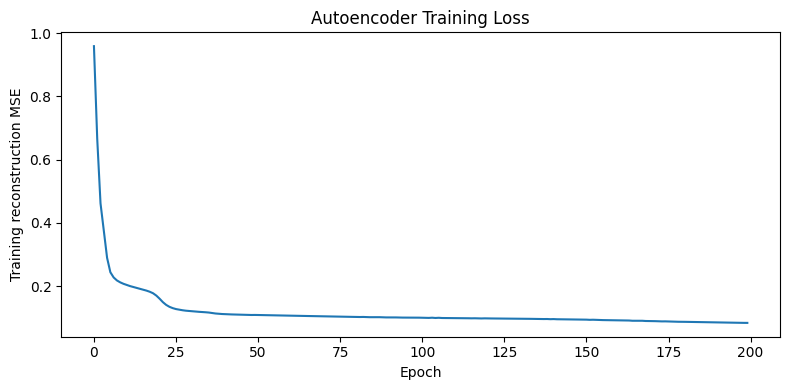

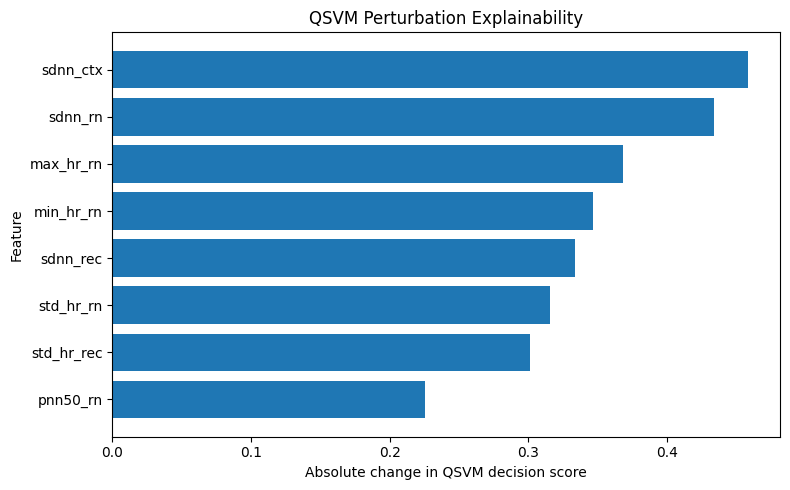

<Figure size 700x500 with 0 Axes>

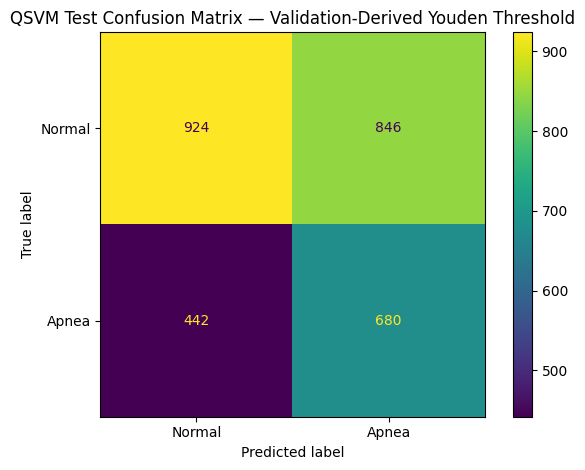

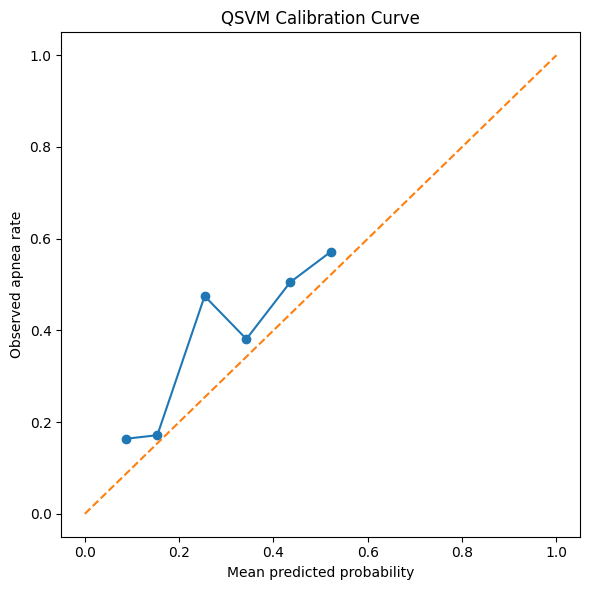

In [39]:
# ============================================================
# STEP 36 — EXPLAINABILITY + PERFORMANCE VISUALIZATIONS
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training reconstruction MSE")
plt.title("Autoencoder Training Loss")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plot_df = explainability_df.head(8).sort_values(
    "absolute_influence",
    ascending=True
)
plt.barh(
    plot_df["feature"],
    plot_df["absolute_influence"]
)
plt.xlabel("Absolute change in QSVM decision score")
plt.ylabel("Feature")
plt.title("QSVM Perturbation Explainability")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    (qsvm_test_scores >= QSVM_THRESHOLD_YOUDEN).astype(int),
    display_labels=["Normal", "Apnea"],
)
plt.title("QSVM Test Confusion Matrix — Validation-Derived Youden Threshold")
plt.tight_layout()
plt.show()

# Calibration curve
prob_true, prob_pred = calibration_curve(
    y_test,
    qsvm_test_calibrated_probability,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(6, 6))
plt.plot(prob_pred, prob_true, marker="o")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed apnea rate")
plt.title("QSVM Calibration Curve")
plt.tight_layout()
plt.show()

In [40]:
# ============================================================
# STEP 37 — FINAL PIPELINE OBJECT / LEAKAGE SANITY CHECK
# ============================================================

required_names = [
    "df",
    "train_df",
    "val_df",
    "test_df",
    "X_train_selected",
    "X_val_selected",
    "X_test_selected",
    "X_train_ae",
    "X_val_ae",
    "X_test_ae",
    "X_train_ae_scaled",
    "X_val_ae_scaled",
    "X_test_ae_scaled",
    "X_q_train",
    "y_q_train",
    "K_q_train",
    "K_q_val_svc",
    "K_q_test_svc",
    "final_qsvm",
    "calibrator",
    "feature_map",
    "train_states",
    "scaler_selected",
    "ae_latent_scaler",
    "quantum_angle_scaler",
]

missing_names = [name for name in required_names if name not in globals()]

assert not missing_names, f"Missing pipeline objects: {missing_names}"

assert len(train_df) == len(y_train)
assert len(val_df) == len(y_val)
assert len(test_df) == len(y_test)

assert not (set(train_records) & set(val_records))
assert not (set(train_records) & set(test_records))
assert not (set(val_records) & set(test_records))

assert np.isfinite(K_q_train).all()
assert np.isfinite(K_q_val_svc).all()
assert np.isfinite(K_q_test_svc).all()

print("All required objects exist.")
print("No record-level split overlap.")
print("Quantum kernel matrices are finite.")
print("Pipeline sanity checks PASSED.")

All required objects exist.
No record-level split overlap.
Quantum kernel matrices are finite.
Pipeline sanity checks PASSED.


In [46]:
import joblib
import json
import numpy as np
import torch

# ============================================================
# STEP 38 — SAVE TRAINED MODELS / SCALERS / METADATA
# ============================================================

joblib.dump(scaler_selected, MODEL_DIR / "selected_feature_scaler.joblib")
joblib.dump(ae_latent_scaler, MODEL_DIR / "ae_latent_scaler.joblib")
joblib.dump(quantum_angle_scaler, MODEL_DIR / "quantum_angle_scaler.joblib")

joblib.dump(pca, MODEL_DIR / "pca_4d.joblib")
joblib.dump(svm_10d, MODEL_DIR / "svm_10d.joblib")
joblib.dump(svm_pca, MODEL_DIR / "svm_pca_4d.joblib")
joblib.dump(svm_ae, MODEL_DIR / "svm_ae_4d_fixed.joblib")
joblib.dump(ae_svm_tuned, MODEL_DIR / "svm_ae_4d_tuned.joblib")
joblib.dump(final_qsvm, MODEL_DIR / "qsvm_precomputed.joblib")
joblib.dump(feature_map, MODEL_DIR / "qsvm_feature_map.joblib")
joblib.dump(calibrator, MODEL_DIR / "qsvm_sigmoid_calibrator.joblib")

torch.save(ae.state_dict(), MODEL_DIR / "hrv_autoencoder_state_dict.pt")

np.save(MODEL_DIR / "qsvm_train_indices.npy", qs_train_idx)
np.save(MODEL_DIR / "qsvm_train_states.npy", train_states)

metadata = {
    "seed": SEED,
    "selected_features": SELECTED_FEATURES,
    "ae_latent_dim": AE_LATENT_DIM,
    "pca_latent_dim": PCA_LATENT_DIM,
    "qsvm_train_per_class": QSVM_TRAIN_PER_CLASS,
    "qsvm_selected_C": BEST_QSVM_C,
    "qsvm_alpha": BEST_ALPHA,
    "qsvm_reps": int(best['reps']),
    "qsvm_youden_threshold": QSVM_THRESHOLD_YOUDEN,
    "qsvm_f1_threshold": QSVM_THRESHOLD_F1,
    "train_records": train_records,
    "validation_records": val_records,
    "test_records": test_records,
}

with open(MODEL_DIR / "pipeline_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Model artifacts saved to:", MODEL_DIR)

Model artifacts saved to: /content/SIH_2026_Apnea/models


In [47]:
# ============================================================
# STEP 39 — FINAL RUN SUMMARY
# ============================================================

# Validation-based operating configuration
primary_validation = {
    "AE-SVM tuned C": best_ae_C,
    "AE-SVM tuned gamma": best_ae_gamma,
    "QSVM C": BEST_QSVM_C,
    "QSVM threshold (Youden)": QSVM_THRESHOLD_YOUDEN,
}

print("=" * 80)
print("FINAL RUN SUMMARY")
print("=" * 80)

print("\nDataset:")
print(split_summary.to_string(index=False))

print("\nRepresentation:")
print(representation_comparison.round(4).to_string(index=False))

print("\nSelected validation configuration:")
for key, value in primary_validation.items():
    print(f"{key}: {value}")

print("\nGenerated result files:")
for path in sorted(RESULT_DIR.glob("*.csv")):
    print(" -", path.name)

print("\nGenerated model files:")
for path in sorted(MODEL_DIR.iterdir()):
    print(" -", path.name)

print("\n" + "=" * 80)
print("PIPELINE COMPLETE")
print("=" * 80)

FINAL RUN SUMMARY

Dataset:
     split  records  rows  apnea  apnea_ratio
     Train       23 11213   4643     0.414073
Validation        6  2899    748     0.258020
      Test        6  2892   1122     0.387967

Representation:
     Method  Original_Dimensions  Reduced_Dimensions  Variance_Retained  Validation_Reconstruction_MSE  Training_Silhouette
        PCA                   10                   4             0.8639                            NaN               0.0753
Autoencoder                   10                   4                NaN                         0.5461               0.0633

Selected validation configuration:
AE-SVM tuned C: 10.0
AE-SVM tuned gamma: 1.0
QSVM C: 10.0
QSVM threshold (Youden): 0.1737780177489805

Generated result files:
 - ae_rbf_svm_tuned_results.csv
 - classical_baselines_results.csv
 - grouped_cv_all_models.csv
 - grouped_cv_summary.csv
 - model_comparison_classical_qsvm_vqc.csv
 - pca_component_loadings.csv
 - pca_explained_variance.csv
 - pca_vs_a

fold1 train:   0%|          | 0/1000 [00:00<?, ?it/s]

fold1 test:   0%|          | 0/3345 [00:00<?, ?it/s]

fold 1/5 done in 83s | test records=6 prevalence=0.378


fold2 train:   0%|          | 0/1000 [00:00<?, ?it/s]

fold2 test:   0%|          | 0/3434 [00:00<?, ?it/s]

...

fold5 train:   0%|          | 0/1000 [00:00<?, ?it/s]

fold5 test:   0%|          | 0/3409 [00:00<?, ?it/s]

fold 5/5 done in 67s | test records=7 prevalence=0.324


,auc_mean,auc_sd,auc_min,auc_max,pr_auc_mean
model,,,,,
10D RBF-SVM,0.7049,0.1215,0.5448,0.8564,0.6365
PCA-4D RBF-SVM,0.6652,0.0945,0.5037,0.7360,0.5280
AE-SVM (full train),0.6467,0.0972,0.4941,0.7543,0.4985
AE-SVM (matched 1000),0.7058,0.0721,0.5836,0.7638,0.5637
QSVM (matched 1000),0.7258,0.0848,0.6010,0.8344,0.5692


Mean fold prevalence (PR-AUC chance level): 0.383

Per-fold AUC difference, QSVM - matched classical: [0.017, 0.015, 0.071, 0.001, -0.004]
  mean=+0.0200  sd=0.0297  folds QSVM wins=4/5
QSVM - full-data AE-SVM: mean=+0.0791
Mean difference is within one SD of the fold-to-fold spread -> no evidence either way.


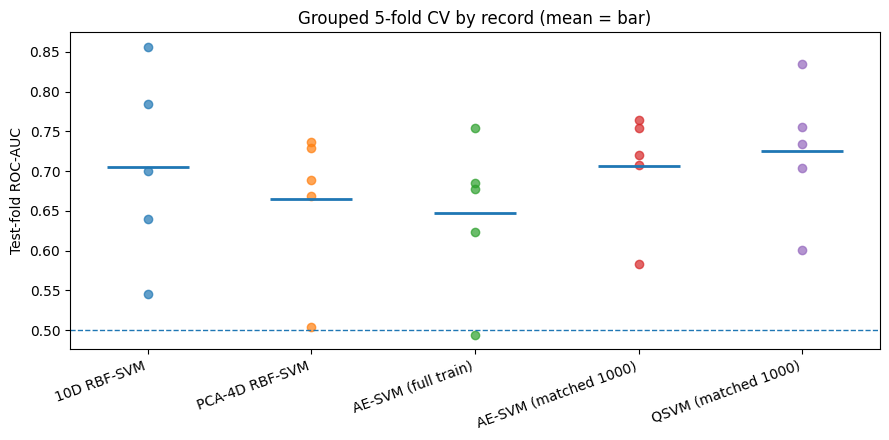

In [48]:
from sklearn.model_selection import GroupKFold
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

N_SPLITS = 5
AE_EPOCHS_CV = 100

# ---------- data: ALL 35 records, c05/c06 kept together ----------
X_all = (df[SELECTED_FEATURES]
         .apply(pd.to_numeric, errors="coerce")
         .replace([np.inf, -np.inf], np.nan))
y_all = df["label"].to_numpy(dtype=int)
rec_all = df["record"].to_numpy()
grp_all = np.where(np.isin(rec_all, ["c05", "c06"]), "c05_c06", rec_all)

gamma_use = best_ae_gamma if isinstance(best_ae_gamma, str) else float(best_ae_gamma)

def train_ae(X, epochs=AE_EPOCHS_CV, seed=SEED):
    torch.manual_seed(seed)
    model = HRVAutoencoder(input_dim=X.shape[1], hidden_dim=AE_HIDDEN_DIM, latent_dim=AE_LATENT_DIM)
    opt = torch.optim.Adam(model.parameters(), lr=AE_LEARNING_RATE, weight_decay=AE_WEIGHT_DECAY)
    loader = DataLoader(
        TensorDataset(torch.tensor(X, dtype=torch.float32)),
        batch_size=AE_BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    for _ in range(epochs):
        model.train()
        for (b,) in loader:
            opt.zero_grad()
            nn.functional.mse_loss(model(b)[0], b).backward()
            opt.step()
    return model.eval()

def encode(model, X):
    with torch.no_grad():
        return model.encoder(torch.tensor(X, dtype=torch.float32)).numpy()

# ---------- CV loop: every fitted object is fit on the fold's TRAIN records only ----------
cv_rows = []
for k, (tr, te) in enumerate(GroupKFold(n_splits=N_SPLITS).split(X_all, y_all, grp_all), 1):
    t0 = time.perf_counter()

    med = X_all.iloc[tr].median()
    Xtr = X_all.iloc[tr].fillna(med).to_numpy(dtype=float)
    Xte = X_all.iloc[te].fillna(med).to_numpy(dtype=float)
    ytr, yte = y_all[tr], y_all[te]

    sc = StandardScaler().fit(Xtr)
    Xtr_s = sc.transform(Xtr).astype(np.float32)
    Xte_s = sc.transform(Xte).astype(np.float32)

    scores = {}

    # 1) 10D RBF-SVM
    m = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced").fit(Xtr_s, ytr)
    scores["10D RBF-SVM"] = m.decision_function(Xte_s)

    # 2) PCA-4D RBF-SVM
    pca_k = PCA(n_components=4, random_state=SEED).fit(Xtr_s)
    m = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced").fit(pca_k.transform(Xtr_s), ytr)
    scores["PCA-4D RBF-SVM"] = m.decision_function(pca_k.transform(Xte_s))

    # 3) AE-4D RBF-SVM (full fold-train, tuned C/gamma)
    ae_k = train_ae(Xtr_s)
    Ztr, Zte = encode(ae_k, Xtr_s), encode(ae_k, Xte_s)
    zsc = StandardScaler().fit(Ztr)
    Ztr_s, Zte_s = zsc.transform(Ztr), zsc.transform(Zte)
    m = SVC(kernel="rbf", C=best_ae_C, gamma=gamma_use, class_weight="balanced").fit(Ztr_s, ytr)
    scores["AE-SVM (full train)"] = m.decision_function(Zte_s)

    # 4) matched classical + 5) QSVM: SAME record-balanced 1000-sample subset
    idx = record_balanced_indices(ytr, rec_all[tr], n_per_class=QSVM_TRAIN_PER_CLASS, seed=SEED)

    zsc_m = StandardScaler().fit(Ztr[idx])
    m = SVC(kernel="rbf", C=best_matched_C, gamma="scale").fit(zsc_m.transform(Ztr[idx]), ytr[idx])
    scores["AE-SVM (matched 1000)"] = m.decision_function(zsc_m.transform(Zte))

    ang = MinMaxScaler(feature_range=(0.0, np.pi)).fit(Ztr_s)
    Qtr = np.clip(ang.transform(Ztr_s[idx]), 0, np.pi).astype(np.float32) * BEST_ALPHA
    Qte = np.clip(ang.transform(Zte_s), 0, np.pi).astype(np.float32) * BEST_ALPHA
    st_tr = statevectors_from_features(Qtr, feature_map, desc=f"fold{k} train")
    st_te = statevectors_from_features(Qte, feature_map, desc=f"fold{k} test")
    q = SVC(kernel="precomputed", C=BEST_QSVM_C).fit(fidelity_kernel_from_states(st_tr, st_tr), ytr[idx])
    scores["QSVM (matched 1000)"] = q.decision_function(fidelity_kernel_from_states(st_te, st_tr))

    for name, s in scores.items():
        cv_rows.append({
            "fold": k, "model": name,
            "n_test_records": len(np.unique(grp_all[te])),
            "prevalence": yte.mean(),
            "auc": roc_auc_score(yte, s),
            "pr_auc": average_precision_score(yte, s),
        })
    print(f"fold {k}/{N_SPLITS} done in {time.perf_counter() - t0:.0f}s | "
          f"test records={len(np.unique(grp_all[te]))} prevalence={yte.mean():.3f}")

cv_results = pd.DataFrame(cv_rows)

# ---------- summary ----------
order = ["10D RBF-SVM", "PCA-4D RBF-SVM", "AE-SVM (full train)",
         "AE-SVM (matched 1000)", "QSVM (matched 1000)"]
summary_cv = (cv_results.groupby("model")
              .agg(auc_mean=("auc", "mean"), auc_sd=("auc", lambda s: s.std(ddof=1)),
                   auc_min=("auc", "min"), auc_max=("auc", "max"),
                   pr_auc_mean=("pr_auc", "mean"))
              .reindex(order))
display(summary_cv.round(4))
print("Mean fold prevalence (PR-AUC chance level):", round(cv_results["prevalence"].mean(), 3))

# ---------- paired comparison on identical folds and identical 1000 training samples ----------
piv = cv_results.pivot(index="fold", columns="model", values="auc")
d_q = piv["QSVM (matched 1000)"] - piv["AE-SVM (matched 1000)"]
d_full = piv["QSVM (matched 1000)"] - piv["AE-SVM (full train)"]
print("\nPer-fold AUC difference, QSVM - matched classical:", d_q.round(3).tolist())
print(f"  mean={d_q.mean():+.4f}  sd={d_q.std(ddof=1):.4f}  folds QSVM wins={(d_q > 0).sum()}/{N_SPLITS}")
print(f"QSVM - full-data AE-SVM: mean={d_full.mean():+.4f}")
if abs(d_q.mean()) < d_q.std(ddof=1):
    print("Mean difference is within one SD of the fold-to-fold spread -> no evidence either way.")

# ---------- plot ----------
plt.figure(figsize=(9, 4.5))
for i, name in enumerate(order):
    v = piv[name].to_numpy()
    plt.scatter(np.full(len(v), i), v, alpha=0.7)
    plt.hlines(v.mean(), i - 0.25, i + 0.25, linewidth=2)
plt.xticks(range(len(order)), order, rotation=20, ha="right")
plt.axhline(0.5, linestyle="--", linewidth=1)
plt.ylabel("Test-fold ROC-AUC")
plt.title(f"Grouped {N_SPLITS}-fold CV by record (mean = bar)")
plt.tight_layout(); plt.show()

cv_results.to_csv(RESULT_DIR / "grouped_cv_all_models.csv", index=False)
summary_cv.to_csv(RESULT_DIR / "grouped_cv_summary.csv")

Trainable circuit parameters: 12
VQC fit time: 410.9s | iterations logged: 90


,split,accuracy,sensitivity,specificity,f1,roc_auc,pr_auc
0,validation,0.5009,0.6123,0.4621,0.3876,0.4803,0.2314
1,test,0.5965,0.7371,0.5073,0.5863,0.7057,0.5794


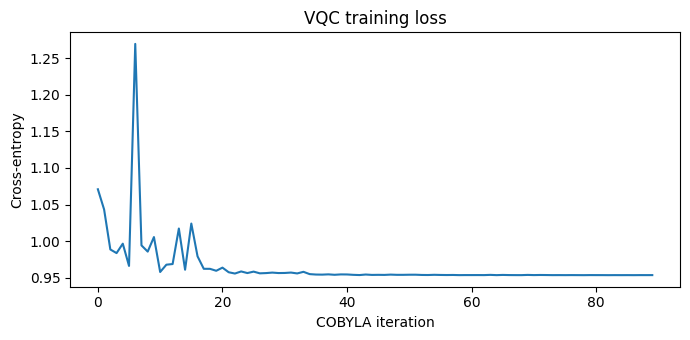

In [49]:
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA

VQC_TRAIN_PER_CLASS = 300     # 600 samples total (simulator cost)
VQC_MAXITER = 100
VQC_ALPHA = BEST_ALPHA        # same bandwidth as the QSVM, no extra tuning on test
VQC_FM_REPS = 1
VQC_ANSATZ_REPS = 2

vqc_idx = record_balanced_indices(
    y_train, train_sample_records,
    n_per_class=VQC_TRAIN_PER_CLASS, seed=SEED
)
X_vqc_train = X_quantum_train_all[vqc_idx] * VQC_ALPHA
y_vqc_train = y_train[vqc_idx]

vqc_fm = zz_feature_map(feature_dimension=4, reps=VQC_FM_REPS, entanglement="linear")
vqc_ansatz = real_amplitudes(num_qubits=4, reps=VQC_ANSATZ_REPS)
print("Trainable circuit parameters:", vqc_ansatz.num_parameters)

vqc_loss_history = []
def vqc_callback(weights, loss):
    vqc_loss_history.append(float(loss))

vqc = VQC(
    feature_map=vqc_fm,
    ansatz=vqc_ansatz,
    loss="cross_entropy",
    optimizer=COBYLA(maxiter=VQC_MAXITER),
    initial_point=np.random.default_rng(SEED).uniform(-np.pi, np.pi, vqc_ansatz.num_parameters),
    sampler=StatevectorSampler(seed=SEED),
    callback=vqc_callback,
)

t0 = time.perf_counter()
vqc.fit(X_vqc_train, y_vqc_train)
vqc_fit_time = time.perf_counter() - t0
print(f"VQC fit time: {vqc_fit_time:.1f}s | iterations logged: {len(vqc_loss_history)}")

def vqc_scores(model, X, alpha=VQC_ALPHA, batch=500):
    X = np.asarray(X) * alpha
    p1 = []
    for s in range(0, len(X), batch):
        out = model.neural_network.forward(X[s:s + batch], model.weights)
        p1.append(np.asarray(out)[:, 1])          # P(class = apnea)
    p1 = np.clip(np.concatenate(p1), 1e-6, 1 - 1e-6)
    return np.log(p1 / (1 - p1)), p1              # logit score, probability

vqc_val_scores, vqc_val_p = vqc_scores(vqc, X_quantum_val)
vqc_test_scores, vqc_test_p = vqc_scores(vqc, X_quantum_test)

vqc_val_row = evaluate_scores(y_val, vqc_val_scores, "validation", 0.0, "VQC", "4D_AE_600_balanced")
vqc_test_row = evaluate_scores(y_test, vqc_test_scores, "test", 0.0, "VQC", "4D_AE_600_balanced")

display(pd.DataFrame([vqc_val_row, vqc_test_row])[
    ["split", "accuracy", "sensitivity", "specificity", "f1", "roc_auc", "pr_auc"]].round(4))

plt.figure(figsize=(7, 3.5))
plt.plot(vqc_loss_history)
plt.xlabel("COBYLA iteration"); plt.ylabel("Cross-entropy"); plt.title("VQC training loss")
plt.tight_layout(); plt.show()

In [50]:
def record_bootstrap_auc(y, scores, records, n_boot=500, seed=SEED):
    y, scores, records = map(np.asarray, (y, scores, records))
    rng = np.random.default_rng(seed)
    recs = np.unique(records)
    idx_by = {r: np.where(records == r)[0] for r in recs}
    aucs = []
    for _ in range(n_boot):
        pick = rng.choice(recs, len(recs), replace=True)
        idx = np.concatenate([idx_by[r] for r in pick])
        if len(np.unique(y[idx])) < 2:
            continue
        aucs.append(roc_auc_score(y[idx], scores[idx]))
    return np.percentile(aucs, [2.5, 97.5])

candidates = {
    "AE-RBF-SVM (full train)":     (ae_tuned_val_scores, ae_tuned_test_scores),
    "AE-RBF-SVM (matched 1000)":   (matched_val_scores, matched_test_scores),
    "QSVM (ZZ kernel, 1000)":      (qsvm_val_scores, qsvm_test_scores),
    "VQC (RealAmplitudes, 600)":   (vqc_val_scores, vqc_test_scores),
}

rows = []
for name, (sv, st) in candidates.items():
    lo, hi = record_bootstrap_auc(y_test, st, test_df["record"].to_numpy())
    rows.append({
        "model": name,
        "val_auc": roc_auc_score(y_val, sv),
        "test_auc": roc_auc_score(y_test, st),
        "test_auc_95ci": f"[{lo:.3f}, {hi:.3f}]",
        "test_pr_auc": average_precision_score(y_test, st),
    })

comparison_df = pd.DataFrame(rows)
display(comparison_df.round(4))
print("Test prevalence (PR-AUC chance level):", round(float(y_test.mean()), 4))
comparison_df.to_csv(RESULT_DIR / "model_comparison_classical_qsvm_vqc.csv", index=False)

,model,val_auc,test_auc,test_auc_95ci,test_pr_auc
0,AE-RBF-SVM (full train),0.6951,0.4880,"[0.353, 0.720]",0.3770
1,AE-RBF-SVM (matched 1000),0.6251,0.6309,"[0.494, 0.789]",0.4814
2,"QSVM (ZZ kernel, 1000)",0.6565,0.5925,"[0.413, 0.779]",0.4466
3,"VQC (RealAmplitudes, 600)",0.4803,0.7057,"[0.543, 0.821]",0.5794


Test prevalence (PR-AUC chance level): 0.388


In [51]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_curve

# ---------- reusable leak-free pipeline: scaler -> AE -> latent scaler -> RBF-SVM ----------
AE_EPOCHS_CV = 100

def train_ae(X, epochs=AE_EPOCHS_CV, seed=SEED):
    torch.manual_seed(seed)
    model = HRVAutoencoder(input_dim=X.shape[1], hidden_dim=AE_HIDDEN_DIM, latent_dim=AE_LATENT_DIM)
    opt = torch.optim.Adam(model.parameters(), lr=AE_LEARNING_RATE, weight_decay=AE_WEIGHT_DECAY)
    loader = DataLoader(
        TensorDataset(torch.tensor(X, dtype=torch.float32)),
        batch_size=AE_BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    for _ in range(epochs):
        model.train()
        for (b,) in loader:
            opt.zero_grad()
            loss = nn.functional.mse_loss(model(b)[0], b)
            loss.backward()
            opt.step()
    return model.eval()

class AESVMPipeline:
    def __init__(self, C, gamma, epochs=AE_EPOCHS_CV, seed=SEED):
        self.C, self.gamma, self.epochs, self.seed = C, gamma, epochs, seed

    def _encode(self, Xs):
        with torch.no_grad():
            return self.ae.encoder(torch.tensor(Xs, dtype=torch.float32)).numpy()

    def fit(self, X_raw, y):
        self.sc = StandardScaler().fit(X_raw)
        Xs = self.sc.transform(X_raw).astype(np.float32)
        self.ae = train_ae(Xs, self.epochs, self.seed)
        Z = self._encode(Xs)
        self.zsc = StandardScaler().fit(Z)
        self.svm = SVC(kernel="rbf", C=self.C, gamma=self.gamma,
                       class_weight="balanced").fit(self.zsc.transform(Z), y)
        return self

    def score(self, X_raw):
        Xs = self.sc.transform(X_raw).astype(np.float32)
        return self.svm.decision_function(self.zsc.transform(self._encode(Xs)))

# ---------- pooled train+val records (c05/c06 stay together) ----------
X_pool = pd.concat([X_train_selected_df, X_val_selected_df]).to_numpy(dtype=float)
y_pool = np.concatenate([y_train, y_val])
rec_pool = np.concatenate([train_df["record"].to_numpy(), val_df["record"].to_numpy()])
grp_pool = np.where(np.isin(rec_pool, ["c05", "c06"]), "c05_c06", rec_pool)

gamma_use = best_ae_gamma if isinstance(best_ae_gamma, str) else float(best_ae_gamma)

oof_scores = np.zeros(len(y_pool))
fold_rows = []
for k, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X_pool, y_pool, grp_pool), 1):
    pipe = AESVMPipeline(C=best_ae_C, gamma=gamma_use).fit(X_pool[tr], y_pool[tr])
    oof_scores[te] = pipe.score(X_pool[te])
    fold_rows.append({"fold": k, "n_test_records": len(np.unique(grp_pool[te])),
                      "prevalence": y_pool[te].mean(),
                      "auc": roc_auc_score(y_pool[te], oof_scores[te])})
    print(f"fold {k}: AUC={fold_rows[-1]['auc']:.4f}")

cv_df = pd.DataFrame(fold_rows)
print(f"\nGrouped-CV AUC: {cv_df['auc'].mean():.4f} ± {cv_df['auc'].std(ddof=1):.4f}")
print(f"Out-of-fold pooled AUC: {roc_auc_score(y_pool, oof_scores):.4f}")

# ---------- threshold tuning on OUT-OF-FOLD scores ----------
SENS_TARGET = 0.85     # below t_low  -> few apnea minutes missed
SPEC_TARGET = 0.85     # above t_high -> few false alarms

def tune_thresholds(y, s, sens_target=SENS_TARGET, spec_target=SPEC_TARGET):
    fpr, tpr, thr = roc_curve(y, s)
    t_youden = float(thr[np.argmax(tpr - fpr)])
    t_low = float(thr[np.where(tpr >= sens_target)[0][0]])        # highest thr with sens >= target
    t_high = float(thr[np.where(1 - fpr >= spec_target)[0][-1]])  # lowest thr with spec >= target
    return {"youden": t_youden, "low": t_low, "high": t_high}

THRESHOLDS = tune_thresholds(y_pool, oof_scores)
print("\nOOF-derived thresholds:", {k: round(v, 4) for k, v in THRESHOLDS.items()})
if THRESHOLDS["low"] >= THRESHOLDS["high"]:
    print("WARNING: sens/spec targets overlap -> model too weak for 3 tiers; "
          "relax targets (e.g. 0.80) or use 2 tiers (Youden only).")

def assign_tier(score, th=THRESHOLDS):
    return np.select([score >= th["high"], score >= th["low"]],
                     ["High", "Moderate"], default="Low")

# ---------- final model on ALL pooled records; test used once ----------
final_pipe = AESVMPipeline(C=best_ae_C, gamma=gamma_use).fit(X_pool, y_pool)
test_raw = X_test_selected_df.to_numpy(dtype=float)
final_test_scores = final_pipe.score(test_raw)

lo, hi = record_bootstrap_auc(y_test, final_test_scores, test_df["record"].to_numpy())
print(f"\nTEST AUC={roc_auc_score(y_test, final_test_scores):.4f}  95% CI [{lo:.3f}, {hi:.3f}] | "
      f"PR-AUC={average_precision_score(y_test, final_test_scores):.4f} "
      f"(chance={y_test.mean():.3f})")

op_rows = [evaluate_scores(y_test, final_test_scores, "test", t, "AE-SVM", name)
           for name, t in [("Youden (OOF)", THRESHOLDS["youden"]),
                           ("High-sensitivity (OOF)", THRESHOLDS["low"]),
                           ("High-specificity (OOF)", THRESHOLDS["high"])]]
display(pd.DataFrame(op_rows)[["representation", "threshold", "sensitivity",
                               "specificity", "precision", "f1"]].round(4))

# ---------- tier table: does the stratification actually separate risk? ----------
tiers_oof = assign_tier(oof_scores)
tiers_test = assign_tier(final_test_scores)

def tier_table(y, tiers):
    t = pd.DataFrame({"tier": tiers, "y": y})
    out = t.groupby("tier")["y"].agg(minutes="size", apnea_rate="mean").reindex(["Low", "Moderate", "High"])
    out["share_of_minutes"] = out["minutes"] / out["minutes"].sum()
    return out

print("\nOut-of-fold tiers:");  display(tier_table(y_pool, tiers_oof).round(3))
print("Held-out TEST tiers:"); display(tier_table(y_test, tiers_test).round(3))
print("A useful stratification has apnea_rate rising monotonically Low < Moderate < High.")

# ---------- probability scores: Platt on OOF scores, judged vs constant baseline ----------
platt = LogisticRegression(C=1.0).fit(oof_scores.reshape(-1, 1), y_pool)
test_prob = platt.predict_proba(final_test_scores.reshape(-1, 1))[:, 1]
p_pool = float(y_pool.mean())
brier_model = brier_score_loss(y_test, test_prob)
brier_const = float(np.mean((y_test - p_pool) ** 2))
print(f"\nTest Brier: model={brier_model:.4f} | constant(pool prevalence)={brier_const:.4f}")
PROB_USEFUL = brier_model < brier_const
print("Probabilities beat baseline -> report as 'risk probability'." if PROB_USEFUL
      else "Probabilities do NOT beat baseline -> report 'risk score + tier' only.")

fold 1: AUC=0.8029
fold 2: AUC=0.7144
fold 3: AUC=0.8489
fold 4: AUC=0.6059
fold 5: AUC=0.6738

Grouped-CV AUC: 0.7292 ± 0.0978
Out-of-fold pooled AUC: 0.7326

OOF-derived thresholds: {'youden': -0.1401, 'low': -0.8648, 'high': 0.8867}

TEST AUC=0.5741  95% CI [0.395, 0.737] | PR-AUC=0.4380 (chance=0.388)


,representation,threshold,sensitivity,specificity,precision,f1
0,Youden (OOF),-0.1401,0.7308,0.3847,0.4295,0.5411
1,High-sensitivity (OOF),-0.8648,0.9260,0.2028,0.4241,0.5817
2,High-specificity (OOF),0.8867,0.4189,0.6458,0.4284,0.4236



Out-of-fold tiers:


,minutes,apnea_rate,share_of_minutes
tier,,,
Low,4668,0.173,0.331
Moderate,5707,0.377,0.404
High,3737,0.650,0.265


Held-out TEST tiers:


,minutes,apnea_rate,share_of_minutes
tier,,,
Low,442,0.188,0.153
Moderate,1353,0.421,0.468
High,1097,0.428,0.379


A useful stratification has apnea_rate rising monotonically Low < Moderate < High.

Test Brier: model=0.2537 | constant(pool prevalence)=0.2375
Probabilities do NOT beat baseline -> report 'risk score + tier' only.


In [52]:
from scipy.stats import spearmanr
rs = pd.DataFrame({"r": rec_pool, "s": oof_scores, "y": y_pool}).groupby("r").mean()
print(spearmanr(rs["s"], rs["y"]))

SignificanceResult(statistic=np.float64(0.3514046755029762), pvalue=np.float64(0.061588231904861596))


In [53]:
DISCLAIMER = "Model-generated risk indication from HRV only; not a clinical diagnosis."

def risk_report(feature_df):
    """feature_df: per-minute HRV features with the SELECTED_FEATURES columns."""
    X = (feature_df[SELECTED_FEATURES]
         .apply(pd.to_numeric, errors="coerce")
         .replace([np.inf, -np.inf], np.nan)
         .fillna(train_medians[SELECTED_FEATURES])
         .to_numpy(dtype=float))
    s = final_pipe.score(X)
    out = feature_df[[c for c in ("record", "minute") if c in feature_df.columns]].copy()
    out["risk_score"] = s
    out["risk_tier"] = assign_tier(s)
    out["flag_apnea"] = (s >= THRESHOLDS["youden"]).astype(int)
    if PROB_USEFUL:
        out["risk_probability"] = platt.predict_proba(s.reshape(-1, 1))[:, 1]
    return out

demo = risk_report(test_df.head(10))
display(demo.round(3))
print(DISCLAIMER)

# per-record summary (what a clinician-facing dashboard would show)
rep_all = risk_report(test_df)
rep_all["label"] = y_test
summary = (rep_all.groupby("record")
           .agg(minutes=("risk_score", "size"),
                pct_high=("risk_tier", lambda s: (s == "High").mean()),
                pct_flagged=("flag_apnea", "mean"),
                true_apnea_rate=("label", "mean"))
           .round(3))
display(summary)

# ---------- persist ----------
joblib.dump(final_pipe.sc, MODEL_DIR / "dx_scaler.joblib")
joblib.dump(final_pipe.zsc, MODEL_DIR / "dx_latent_scaler.joblib")
joblib.dump(final_pipe.svm, MODEL_DIR / "dx_svm.joblib")
joblib.dump(platt, MODEL_DIR / "dx_platt.joblib")
torch.save(final_pipe.ae.state_dict(), MODEL_DIR / "dx_autoencoder.pt")
joblib.dump(train_medians[SELECTED_FEATURES], MODEL_DIR / "dx_train_medians.joblib")

with open(MODEL_DIR / "dx_decision_support.json", "w", encoding="utf-8") as f:
    json.dump({
        "thresholds_oof": THRESHOLDS,
        "sens_target": SENS_TARGET, "spec_target": SPEC_TARGET,
        "selected_features": SELECTED_FEATURES,
        "probabilities_reported": bool(PROB_USEFUL),
        "grouped_cv_auc_mean": float(cv_df["auc"].mean()),
        "grouped_cv_auc_sd": float(cv_df["auc"].std(ddof=1)),
        "disclaimer": DISCLAIMER,
    }, f, indent=2)
print("Saved decision-support artifacts.")

,record,minute,risk_score,risk_tier,flag_apnea
489,a02,0,-0.543,Moderate,0
490,a02,1,-0.509,Moderate,0
491,a02,2,-0.674,Moderate,0
492,a02,3,-0.701,Moderate,0
493,a02,4,-0.653,Moderate,0
494,a02,5,0.268,Moderate,1
495,a02,6,1.414,High,1
496,a02,7,2.200,High,1
497,a02,8,-0.687,Moderate,0
498,a02,9,-0.048,Moderate,1


Model-generated risk indication from HRV only; not a clinical diagnosis.


,minutes,pct_high,pct_flagged,true_apnea_rate
record,,,,
a02,528,0.523,0.795,0.795
a16,482,0.398,0.836,0.664
a20,510,0.027,0.231,0.618
b04,426,0.364,0.702,0.023
b05,433,0.716,0.831,0.132
c08,513,0.292,0.602,0.000


Saved decision-support artifacts.
